# THz Sensor Characterization — TFLN EO Detector at AWA

**Objective.** Characterize the interaction between the Partow/RPI thin-film lithium niobate (TFLN) Mach–Zehnder EO sensor and the THz E-field generated at AWA by varying bunch charge. Build a Lorentz-transformed E-field model from the measured charge and compare to the detector response using the Wilke et al. (*Sci. Rep.* 14, 4822, 2024) sensitivity relations.

**Dataset.** July 31, 2025 fine scans, charge sweep 0.25 → 10 nC (`Data_raw/July31_/finescaneQ*.npz`).

**Notebook outline.**
1. Load dataset (BPD + ICT + phase axis)
2. BPD analysis — raw waveforms, EO magnitude, integrated voltage
3. Heatmaps over (phase delay, scope time)
4. ICT physical charge per shot using $Q = 0.8\,|\!\int V\,dt|$
5. BPD response vs. measured charge
6. Lorentz-transformed E-field model of the bunch field
7. Convert BPD signal → detected E-field via Wilke et al. half-wave relation and compare

In [ ]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, epsilon_0, e as q_e

# Anchor cwd at project root so paths work whether the notebook is run from Analysis/ or repo root
if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')
os.makedirs('Results', exist_ok=True)
os.makedirs('Results/heatmaps', exist_ok=True)

# ─── instrument constants ──────────────────────────────────────────────────
RF_HZ       = 81.25e6            # phase encoded against 81.25 MHz reference
T_LASER_NS  = 1e9 / RF_HZ        # 12.31 ns laser period
MV          = 1e3                # V → mV scale

# ─── BPD scope ─────────────────────────────────────────────────────────────
BPD_N           = 5000           # samples per shot (50 GS/s, 100 ns window)
BPD_DT_NS       = 20e-3          # 20 ps / sample
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 100
FFT_SIGMA_GHZ   = 0.35
FFT_ORDER       = 6
PROBE_HALF_WIN  = 25             # samples around the EO probe pulse for the signed amplitude

# ─── ICT digitiser ─────────────────────────────────────────────────────────
ICT_BL_PRE      = slice(None, 700)
ICT_BL_POST     = slice(1300, None)
DT_ICT_NS       = 0.444          # ns/sample; calibrated from nominal-charge fit (per existing ICT notebook)
ICT_K           = 0.8            # nC/(V·ns) — ICT manufacturer constant

# ─── Sensor / beam parameters (from MOP048 & Wilke et al. 2024) ────────────
E_BEAM_MEV  = 60.0                       # AWA linac energy
GAMMA       = E_BEAM_MEV / 0.511         # ~117
BETA        = np.sqrt(1 - 1/GAMMA**2)
LAMBDA_PROBE = 1550e-9                   # m
N_E_LN      = 2.15                       # extraordinary index of LiNbO3 at 1550 nm
R33         = 30.9e-12                   # m/V
L_MZI       = 600e-6                     # m, interferometer arm length
N_RF_FUSED  = 1.95                       # SiO2 index at THz freq
N_OPT_GUIDE = 2.40                       # group index of TE mode in TFLN @ 1550 nm

print(f'γ ≈ {GAMMA:.1f}, β ≈ {BETA:.6f}')
print(f'cwd = {os.getcwd()}')

γ ≈ 117.4, β ≈ 0.999964
cwd = /home/paulrleaa/Documents/1_Research/Suli2026/SULI_THZ_SUM26/.claude/worktrees/unified-thz-analysis


## 1 · Dataset — July 31 fine scans

Each `.npz` packs `BPDwf` (steps, 10 shots, 5000 samples), `ictwf` (steps, 10 shots, 2502 samples), `phase` (steps,) in degrees of the 81.25 MHz reference, and `x` (1, 5000) time axis in seconds. Delay relative to the first phase set-point is
$$t_\text{delay} = \frac{\phi-\phi_0}{360^\circ \cdot f_\text{RF}}.$$

In [ ]:
FINE_SCANS = [
    #{'label': '0.25 nC', 'Q_nom': 0.25, 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    #{'label': '0.5 nC',  'Q_nom': 0.50, 'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    #{'label': '1 nC',    'Q_nom': 1.00, 'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    #{'label': '4 nC',    'Q_nom': 4.00, 'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    #{'label': '5 nC',    'Q_nom': 5.00, 'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    #{'label': '7 nC',    'Q_nom': 7.00, 'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC',   'Q_nom': 10.0, 'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(FINE_SCANS)))

def delay_ps_from_phase(phase_deg):
    return (phase_deg - phase_deg[0]) / RF_HZ / 360 * 1e12

scans = []
for s in FINE_SCANS:
    d = np.load(s['path'])
    rec = {
        'label':    s['label'],
        'Q_nom':    s['Q_nom'],
        'phase':    d['phase'],
        'delay_ps': delay_ps_from_phase(d['phase']),
        't_ns':     1e9 * d['x'][0, :],
        'BPDwf':    d['BPDwf'],   # (steps, 10, 5000)
        'ictwf':    d['ictwf'],   # (steps, 10, 2502)
    }
    scans.append(rec)
    print(f"{s['label']:>8}  steps={len(d['phase']):3d}  "
          f"Δphase={np.ptp(d['phase']):.2f}°  span={np.ptp(rec['delay_ps']):.1f} ps")

 0.25 nC  steps=160  Δphase=3.98°  span=135.9 ps
  0.5 nC  steps=160  Δphase=3.98°  span=135.9 ps
    1 nC  steps=160  Δphase=3.98°  span=135.9 ps
    4 nC  steps=160  Δphase=3.98°  span=135.9 ps
    5 nC  steps=160  Δphase=3.98°  span=135.9 ps
    7 nC  steps=160  Δphase=3.98°  span=135.9 ps
   10 nC  steps=160  Δphase=3.98°  span=135.9 ps


## 2 · BPD analysis — raw waveforms, signed amplitude, integrated voltage

Each scope trace is contaminated by a repeating 81.25 MHz laser train. We isolate the EO-modulated probe pulse by:

1. averaging the 10 shots per phase step,
2. estimating the baseline inside `[SIGNAL_START_NS, SIGNAL_END_NS]` by *period-filling* — replacing samples in the window with the same-phase carrier from the **one clean laser period immediately before the window** (the pre-modulation background), extrapolated across the whole window. The earlier symmetric variant averaged the periods before *and* after; the *after* period is contaminated by an amplitude-dependent post-pulse baseline droop that inflated the recovered signal at high charge, so only the pre-modulation (before) period is used,
3. subtracting the baseline and low-pass filtering with a super-Gaussian FFT filter ($\sigma=0.35$ GHz, order 6),
4. defining the **signed amplitude** as the mean of the residual within $\pm 25$ samples of the highest-variance probe time.

In [ ]:
def _period_fill_indices(t_ns, s0, s1):
    dt = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    T  = T_LASER_NS / dt
    i0, i1 = int(round(s0/dt)), int(round(s1/dt))
    idx = np.arange(i0, i1)
    nl  = np.ceil((idx + 1 - i0) / T).astype(int)
    nr  = np.ceil((i1 - idx)       / T).astype(int)
    return i0, i1, np.round(idx - nl*T).astype(int), np.round(idx + nr*T).astype(int)

def fft_lowpass(arr, dt_ns):
    n = arr.shape[1]
    freqs = np.fft.rfftfreq(n, d=dt_ns)
    H = np.exp(-0.5 * (freqs / FFT_SIGMA_GHZ) ** (2 * FFT_ORDER))
    return np.fft.irfft(np.fft.rfft(arr, axis=1) * H, n=n, axis=1)

def reduce_bpd(rec):
    t_ns   = rec['t_ns']
    raw    = rec['BPDwf']                                       # (steps, n_shots, 5000)
    n_st, n_sh, n_sa = raw.shape
    traces = raw.mean(axis=1)                                   # (steps, 5000)
    dt     = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    i0, i1, sl, sr = _period_fill_indices(t_ns, SIGNAL_START_NS, SIGNAL_END_NS)

    # 10-shot-averaged pipeline.
    # Baseline = the single CLEAN laser period just BEFORE the signal window
    # (sl always lands in [i0-T, i0), i.e. the pre-modulation carrier ~peak 4),
    # tiled across the whole window. The symmetric variant 0.5*(sl + sr) is
    # NOT used because the "after" reference sr falls in the post-probe region,
    # which suffers an amplitude-dependent baseline droop after a strong EO
    # swing and would inflate the recovered signal at high charge. Extrapolating
    # the pre-modulation background forward avoids that contamination.
    bl = traces.copy()
    bl[:, i0:i1] = traces[:, sl]                                # before-window (pre-modulation) period only
    res = fft_lowpass(traces - bl, dt)                          # baseline-subtracted, LP-filtered
    tp  = int(res.var(axis=0).argmax())                          # probe time = highest variance vs delay
    win = slice(max(0, tp - PROBE_HALF_WIN), min(res.shape[1], tp + PROBE_HALF_WIN))
    signed_amp = res[:, win].mean(axis=1)                        # (steps,)  V

    # Per-shot pipeline — same baseline-fill + FFT-LP filter, applied to each
    # individual shot. Yields signed_amp_ps shape (steps, n_shots).
    flat = raw.reshape(-1, n_sa)                                 # (steps*n_shots, 5000)
    bl_s = flat.copy()
    bl_s[:, i0:i1] = flat[:, sl]                                # before-window (pre-modulation) period only
    res_ps = fft_lowpass(flat - bl_s, dt).reshape(n_st, n_sh, n_sa)
    signed_amp_ps = res_ps[:, :, win].mean(axis=-1)              # (steps, n_shots) V

    # Per-shot empirical scatter of each metric — propagates all noise sources
    # (detector + charge fluctuations + timing jitter + real bunch shape var).
    dly_ps             = rec['delay_ps']
    amp_peak_ps        = np.abs(signed_amp_ps).max(axis=0)                          # (n_shots,) V
    p2p_global_ps      = signed_amp_ps.max(axis=0) - signed_amp_ps.min(axis=0)      # (n_shots,) V
    integ_abs_ps       = np.trapezoid(np.abs(signed_amp_ps), dly_ps, axis=0)        # (n_shots,) V·ps
    amp_peak_err       = float(amp_peak_ps  .std(ddof=1) / np.sqrt(n_sh))
    p2p_global_err     = float(p2p_global_ps.std(ddof=1) / np.sqrt(n_sh))
    integ_abs_err      = float(integ_abs_ps .std(ddof=1) / np.sqrt(n_sh))

    return {'traces_raw': traces, 'res': res, 'tp': tp, 'signed_amp': signed_amp,
            'signed_amp_ps': signed_amp_ps, 'n_shots': n_sh,
            'amp_peak_ps':       amp_peak_ps,       'amp_peak_err':   amp_peak_err,
            'p2p_global_ps':     p2p_global_ps,     'p2p_global_err': p2p_global_err,
            'integ_abs_ps':      integ_abs_ps,      'integ_abs_err':  integ_abs_err}

for rec in scans:
    rec.update(reduce_bpd(rec))
    print(f"{rec['label']:>8}  probe@t={rec['t_ns'][rec['tp']]:.2f} ns  "
          f"|amp|_max={MV*np.abs(rec['signed_amp']).max():.2f} mV  "
          f"σ_amp(per-scan)={MV*rec['amp_peak_err']:.3f} mV  "
          f"σ_p2p={MV*rec['p2p_global_err']:.3f} mV  "
          f"σ_int={MV*rec['integ_abs_err']:.3f} mV·ps  "
          f"(n_shots={rec['n_shots']})")

 0.25 nC  probe@t=52.64 ns  |amp|_max=13.21 mV  σ_amp(per-scan)=0.637 mV  σ_p2p=1.169 mV  σ_int=3.718 mV·ps  (n_shots=10)
  0.5 nC  probe@t=52.78 ns  |amp|_max=25.52 mV  σ_amp(per-scan)=0.435 mV  σ_p2p=1.229 mV  σ_int=7.028 mV·ps  (n_shots=10)
    1 nC  probe@t=52.88 ns  |amp|_max=45.83 mV  σ_amp(per-scan)=1.115 mV  σ_p2p=1.351 mV  σ_int=9.553 mV·ps  (n_shots=10)
    4 nC  probe@t=53.06 ns  |amp|_max=130.01 mV  σ_amp(per-scan)=5.770 mV  σ_p2p=11.065 mV  σ_int=34.174 mV·ps  (n_shots=10)
    5 nC  probe@t=51.48 ns  |amp|_max=169.03 mV  σ_amp(per-scan)=4.353 mV  σ_p2p=5.830 mV  σ_int=39.830 mV·ps  (n_shots=10)
    7 nC  probe@t=52.18 ns  |amp|_max=208.71 mV  σ_amp(per-scan)=5.434 mV  σ_p2p=6.124 mV  σ_int=54.014 mV·ps  (n_shots=10)
   10 nC  probe@t=52.48 ns  |amp|_max=245.76 mV  σ_amp(per-scan)=5.871 mV  σ_p2p=10.930 mV  σ_int=66.726 mV·ps  (n_shots=10)


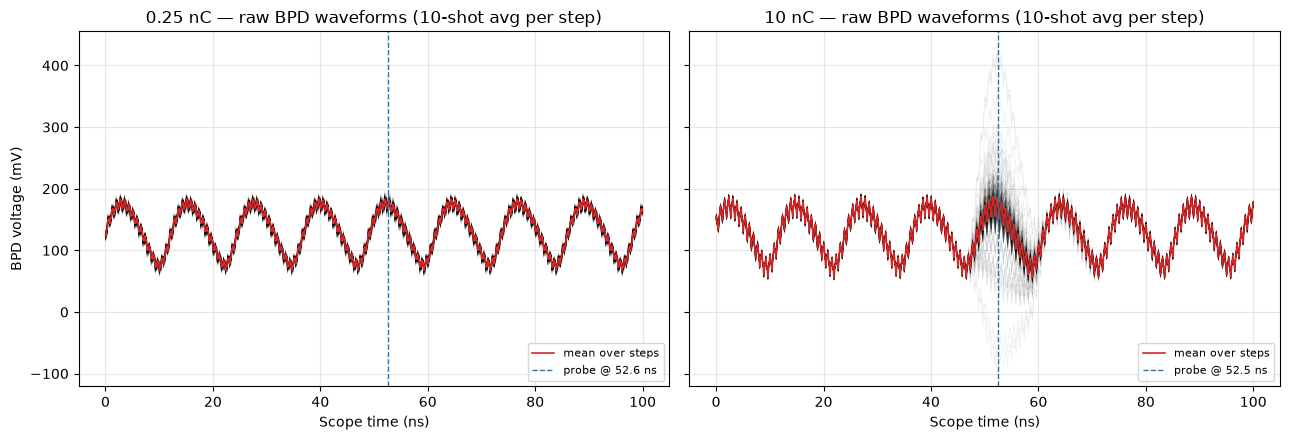

In [ ]:
# ── 2a · raw BPD traces (steps overlaid) for two charge extremes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, idx in zip(axes, [0, -1]):
    rec = scans[idx]
    for step in range(rec['traces_raw'].shape[0]):
        ax.plot(rec['t_ns'], MV*rec['traces_raw'][step], color='k', alpha=0.06, lw=0.5)
    ax.plot(rec['t_ns'], MV*rec['traces_raw'].mean(axis=0), 'C3', lw=1.2, label='mean over steps')
    ax.axvline(rec['t_ns'][rec['tp']], ls='--', color='C0', lw=1, label=f"probe @ {rec['t_ns'][rec['tp']]:.1f} ns")
    ax.set_xlabel('Scope time (ns)'); ax.set_title(f"{rec['label']} — raw BPD waveforms (10-shot avg per step)")
    ax.grid(True, alpha=0.3); ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('BPD voltage (mV)')
plt.tight_layout(); plt.savefig('Results/01_raw_BPD_waveforms.png', dpi=180, bbox_inches='tight'); plt.show()

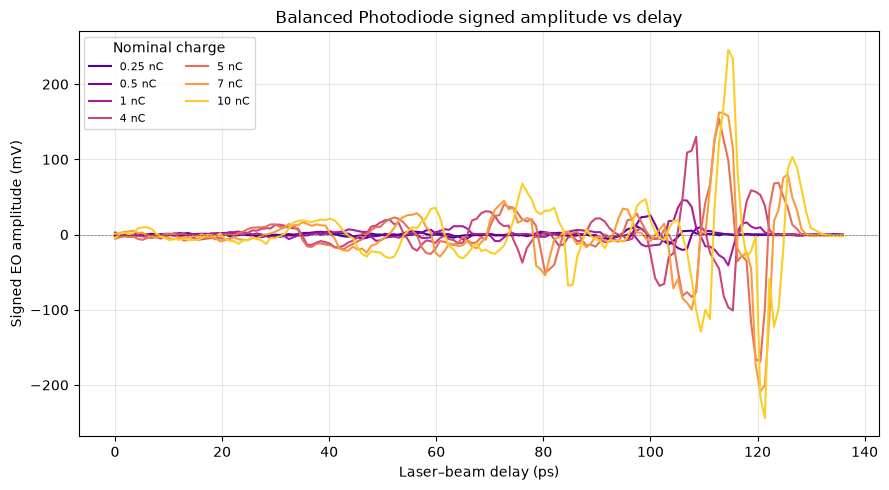

In [ ]:
# ── 2b · signed amplitude vs delay (EO magnitude proxy)
fig, ax = plt.subplots(figsize=(9, 5))
for rec, col in zip(scans, colors):
    ax.plot(rec['delay_ps'], MV*rec['signed_amp'], color=col, lw=1.5, label=rec['label'])
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.5)
ax.set_xlabel('Laser–beam delay (ps)'); ax.set_ylabel('Signed EO amplitude (mV)')
ax.set_title('Balanced Photodiode signed amplitude vs delay')
ax.legend(title='Nominal charge', fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig('Results/02_signed_amp_vs_delay.png', dpi=500, bbox_inches='tight'); plt.show()

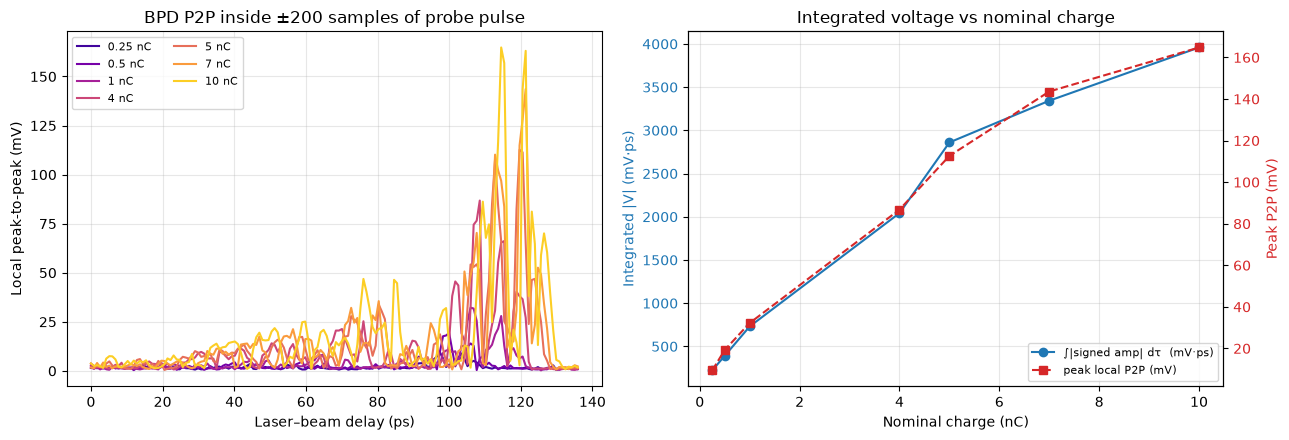

In [ ]:
# ── 2c · integrated |V| over delay  →  the area under the EO envelope
# Two metrics: (i) local P2P inside ±200 samples of the probe; (ii) ∫|signed_amp| dt over the full scan.
summary = []
for rec in scans:
    res = rec['res']; tp = rec['tp']
    half_local = 200
    win = slice(max(0, tp - half_local), min(res.shape[1], tp + half_local))
    p2p   = (res[:, win].max(axis=1) - res[:, win].min(axis=1))            # V vs delay
    integ = np.trapezoid(np.abs(rec['signed_amp']), rec['delay_ps'])        # V·ps
    summary.append({
        'label':       rec['label'],
        'Q_nom':       rec['Q_nom'],
        'p2p_vs_dly':  p2p,
        'p2p_peak':    p2p.max(),
        'amp_peak':    np.abs(rec['signed_amp']).max(),
        'integ_abs':   integ,
    })

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for rec, s, col in zip(scans, summary, colors):
    axes[0].plot(rec['delay_ps'], MV*s['p2p_vs_dly'], color=col, lw=1.5, label=rec['label'])
axes[0].set_xlabel('Laser–beam delay (ps)'); axes[0].set_ylabel('Local peak-to-peak (mV)')
axes[0].set_title('BPD P2P inside ±200 samples of probe pulse')
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8, ncol=2)

Q  = np.array([s['Q_nom']     for s in summary])
Ip = np.array([s['integ_abs'] for s in summary])
Pp = np.array([s['p2p_peak']  for s in summary])
axes[1].plot(Q, MV*Ip, 'o-', color='C0', label='∫|signed amp| dτ  (mV·ps)')
ax2 = axes[1].twinx()
ax2.plot(Q, MV*Pp, 's--', color='C3', label='peak local P2P (mV)')
axes[1].set_xlabel('Nominal charge (nC)'); axes[1].set_ylabel('Integrated |V| (mV·ps)', color='C0')
ax2.set_ylabel('Peak P2P (mV)', color='C3')
axes[1].set_title('Integrated voltage vs nominal charge'); axes[1].grid(True, alpha=0.3)
axes[1].tick_params(axis='y', labelcolor='C0'); ax2.tick_params(axis='y', labelcolor='C3')
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1+h2, l1+l2, loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig('Results/03_integrated_voltage.png', dpi=180, bbox_inches='tight'); plt.show()

### 2d · Simple `max(trace)` and `max − min` as the BPD signature

A simpler background-removal tool: at every delay step, represent the BPD signature by the **plain extrema of the 10-shot-averaged trace along the time axis** — no period-fill, no FFT low-pass, no probe-window mean. The maximum of the periodic laser-pulse train (the "sinusoidal peak") sits at a near-fixed scope time, so its height tracks the EO modulation directly; the `max − min` peak-to-peak version captures the full positive ↔ negative swing.

The first panel marks where in time that peak lives on the mean trace for the two charge extremes. The second figure plots both signatures vs laser–beam delay for every charge — left: `trace.max(time)`, right: `trace.max(time) − trace.min(time)`.

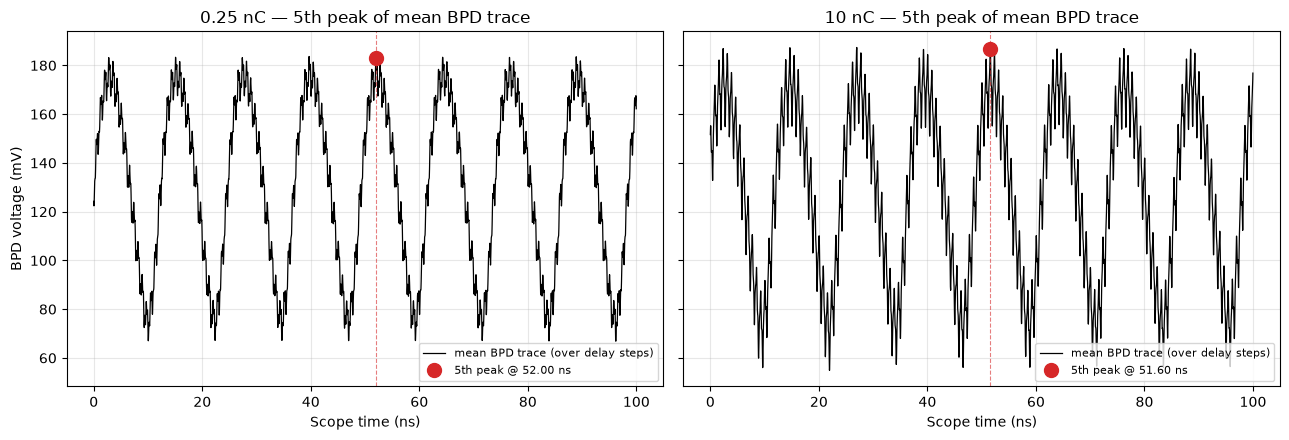

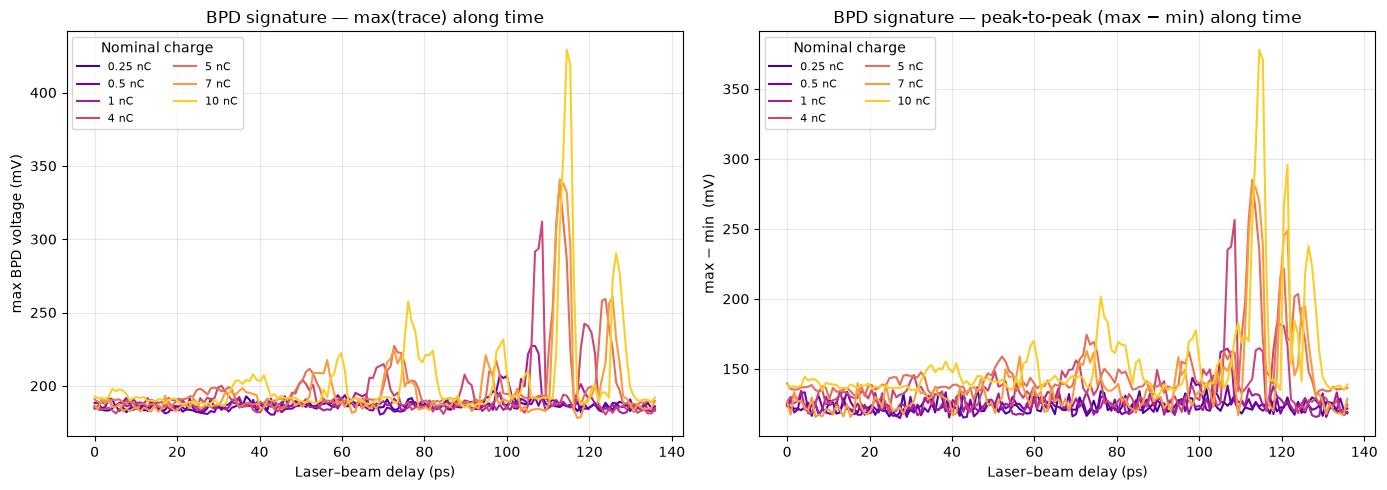

In [ ]:
# ── 2d.1 · Sinusoidal-peak location on the mean BPD trace (two charge extremes)
from scipy.signal import find_peaks

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, idx in zip(axes, [0, -1]):
    rec        = scans[idx]
    mean_trace = rec['traces_raw'].mean(axis=0)            # (5000,) average over delay steps
    dt_ns      = rec['t_ns'][1] - rec['t_ns'][0]
    min_sep    = int(0.8 * T_LASER_NS / dt_ns)
    peak_idxs, _ = find_peaks(mean_trace, distance=min_sep)
    i_peak     = int(peak_idxs[4])                         # 5th peak (0-indexed)
    ax.plot(rec['t_ns'], MV*mean_trace, 'k', lw=0.9, label='mean BPD trace (over delay steps)')
    ax.axvline(rec['t_ns'][i_peak], color='C3', ls='--', lw=0.8, alpha=0.6)
    ax.plot(rec['t_ns'][i_peak], MV*mean_trace[i_peak], 'C3o', ms=10,
            label=f'5th peak @ {rec["t_ns"][i_peak]:.2f} ns')
    ax.set_xlabel('Scope time (ns)')
    ax.set_title(f"{rec['label']} — 5th peak of mean BPD trace")
    ax.grid(True, alpha=0.3); ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('BPD voltage (mV)')
plt.tight_layout()
plt.savefig('Results/03b_sinusoidal_peak.png', dpi=180, bbox_inches='tight')
plt.show()


# ── 2d.2 · BPD signatures vs delay — simple max(trace) and (max-min) peak-to-peak
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for rec, col in zip(scans, colors):
    step_mean   = rec['BPDwf'].mean(axis=1)                # (steps, 5000) 10-shot avg
    bpd_sig_max = step_mean.max(axis=1)                    # (steps,) V
    bpd_sig_p2p = step_mean.max(axis=1) - step_mean.min(axis=1)   # (steps,) V
    rec['bpd_sig_max'] = bpd_sig_max
    rec['bpd_sig_p2p'] = bpd_sig_p2p
    axes[0].plot(rec['delay_ps'], MV*bpd_sig_max, color=col, lw=1.5, label=rec['label'])
    axes[1].plot(rec['delay_ps'], MV*bpd_sig_p2p, color=col, lw=1.5, label=rec['label'])
axes[0].set_xlabel('Laser–beam delay (ps)'); axes[0].set_ylabel('max BPD voltage (mV)')
axes[0].set_title('BPD signature — max(trace) along time')
axes[0].grid(True, alpha=0.3); axes[0].legend(title='Nominal charge', fontsize=8, ncol=2)
axes[1].set_xlabel('Laser–beam delay (ps)'); axes[1].set_ylabel('max − min  (mV)')
axes[1].set_title('BPD signature — peak-to-peak (max − min) along time')
axes[1].grid(True, alpha=0.3); axes[1].legend(title='Nominal charge', fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig('Results/03c_bpd_max_vs_delay.png', dpi=180, bbox_inches='tight')
plt.show()


Found 9 peaks at scope times (ns): [2.36, 14.66, 26.98, 39.28, 51.6, 63.9, 76.2, 88.5, 99.28]


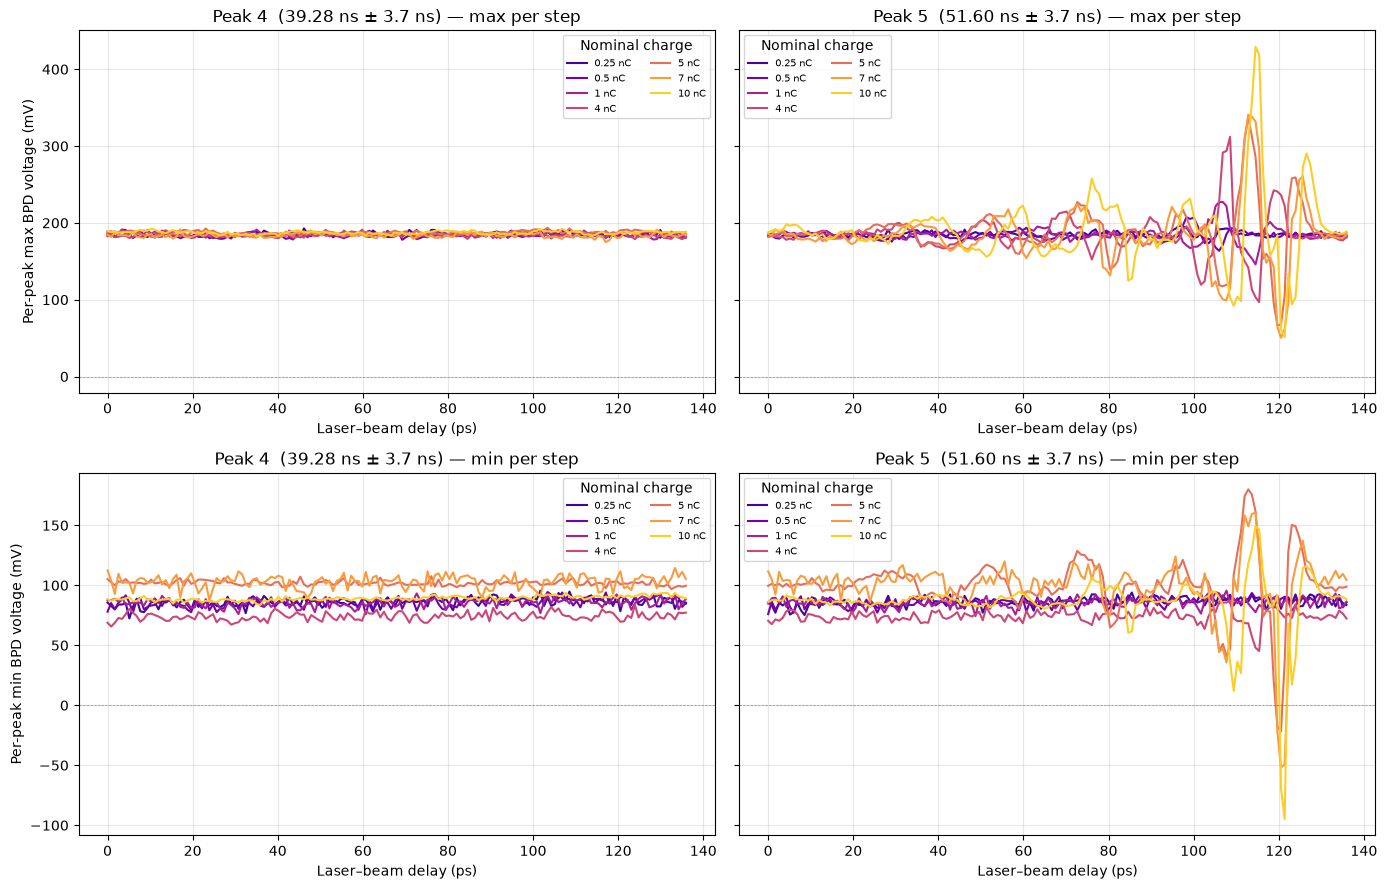

In [ ]:
# ── 2d.3 · Per-peak max and min vs delay — compare the 4th and 5th laser-train peaks
from scipy.signal import find_peaks

rec_ref     = scans[-1]
grand_mean  = rec_ref['traces_raw'].mean(axis=0)
dt_ns       = rec_ref['t_ns'][1] - rec_ref['t_ns'][0]
min_sep     = int(0.8 * T_LASER_NS / dt_ns)
peak_idxs, _ = find_peaks(grand_mean, distance=min_sep)
print(f'Found {len(peak_idxs)} peaks at scope times (ns): '
      f'{rec_ref["t_ns"][peak_idxs].round(2).tolist()}')

half_win = int(0.3 * T_LASER_NS / dt_ns)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey='row')
for col_idx, peak_num in enumerate([4, 5]):
    if peak_num > len(peak_idxs):
        for row in range(2):
            axes[row, col_idx].text(0.5, 0.5, f'peak {peak_num} not found',
                ha='center', va='center', transform=axes[row, col_idx].transAxes)
        continue
    pk_centre = peak_idxs[peak_num - 1]
    win       = slice(max(0, pk_centre - half_win),
                      min(len(rec_ref['t_ns']), pk_centre + half_win))
    t_centre  = rec_ref['t_ns'][pk_centre]
    win_ns    = half_win * dt_ns

    for rec, col in zip(scans, colors):
        step_mean = rec['BPDwf'].mean(axis=1)
        peak_max  = step_mean[:, win].max(axis=1)
        peak_min  = step_mean[:, win].min(axis=1)
        rec[f'bpd_peak{peak_num}_max'] = peak_max
        rec[f'bpd_peak{peak_num}_min'] = peak_min
        kw = dict(color=col, lw=1.5, label=rec['label'])
        axes[0, col_idx].plot(rec['delay_ps'], MV*peak_max, **kw)
        axes[1, col_idx].plot(rec['delay_ps'], MV*peak_min, **kw)

    for row, stat in enumerate(['max', 'min']):
        ax = axes[row, col_idx]
        ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
        ax.set_xlabel('Laser–beam delay (ps)')
        ax.set_title(f'Peak {peak_num}  ({t_centre:.2f} ns ± {win_ns:.1f} ns) — {stat} per step')
        ax.grid(True, alpha=0.3)
        ax.legend(title='Nominal charge', fontsize=7, ncol=2, loc='best')

axes[0, 0].set_ylabel('Per-peak max BPD voltage (mV)')
axes[1, 0].set_ylabel('Per-peak min BPD voltage (mV)')
plt.tight_layout()
plt.savefig('Results/03d_peak4_vs_peak5_max_min.png', dpi=180, bbox_inches='tight')
plt.show()


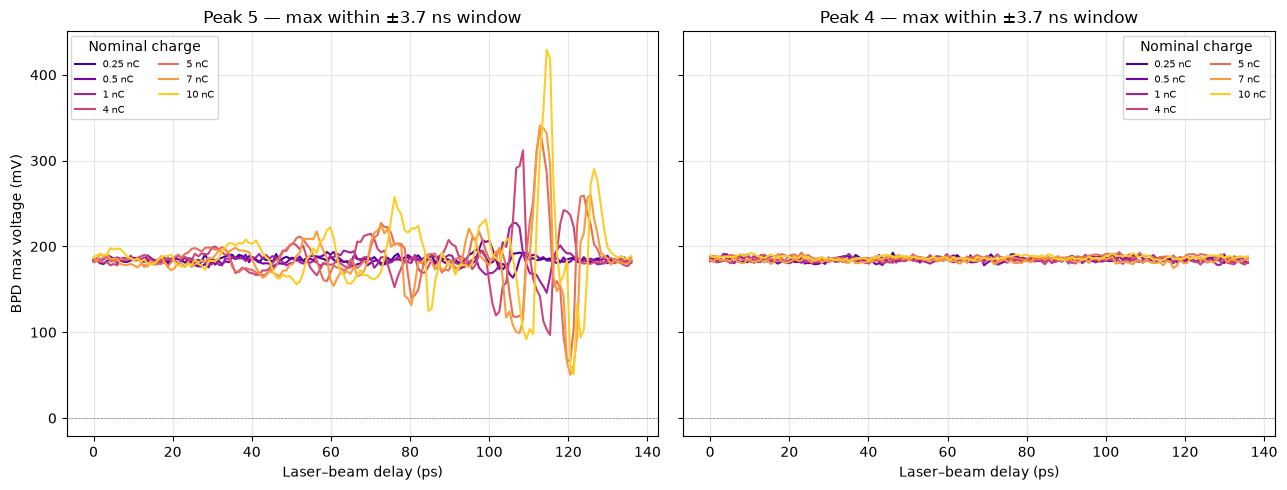

In [ ]:
# ── 2d.6 · Maxima only for peaks 4 and 5 — all charges ──────────────────────
_dt_ns  = scans[0]['t_ns'][1] - scans[0]['t_ns'][0]
_win_ns = int(0.3 * T_LASER_NS / _dt_ns) * _dt_ns      # half-window size in ns

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for rec, col in zip(scans, colors):
    axes[0].plot(rec['delay_ps'], MV*rec['bpd_peak5_max'], color=col, lw=1.5, label=rec['label'])
    axes[1].plot(rec['delay_ps'], MV*rec['bpd_peak4_max'], color=col, lw=1.5, label=rec['label'])
for ax, pk in zip(axes, [5, 4]):
    ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
    ax.set_xlabel('Laser\u2013beam delay (ps)')
    ax.set_title(f'Peak {pk} — max within \u00b1{_win_ns:.1f} ns window')
    ax.grid(True, alpha=0.3)
    ax.legend(title='Nominal charge', fontsize=7, ncol=2)
axes[0].set_ylabel('BPD max voltage (mV)')
plt.tight_layout()
plt.savefig('Results/03e_peak4_peak5_maxima.png', dpi=180, bbox_inches='tight')
plt.show()


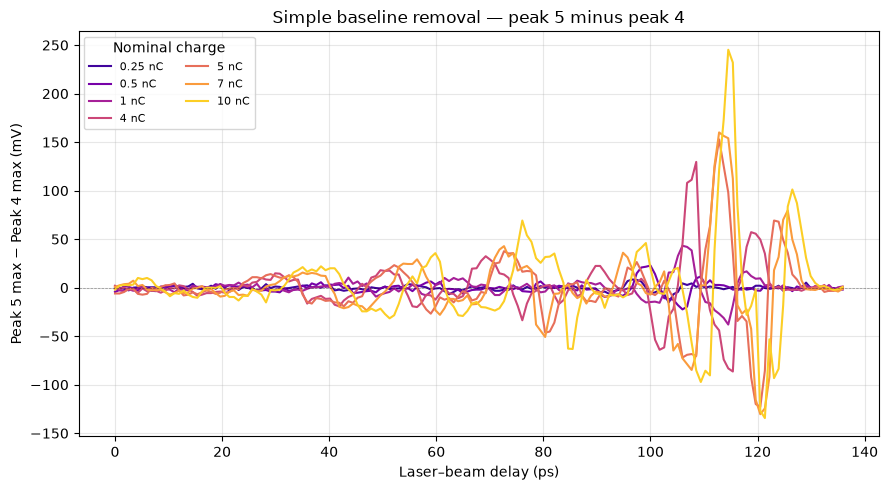

In [ ]:
# ── 2d.7 · Simple baseline removal: peak 5 max − peak 4 max ─────────────────
fig, ax = plt.subplots(figsize=(9, 5))
for rec, col in zip(scans, colors):
    diff = rec['bpd_peak5_max'] - rec['bpd_peak4_max']
    rec['peak_diff'] = diff
    ax.plot(rec['delay_ps'], MV*diff, color=col, lw=1.5, label=rec['label'])
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_xlabel('Laser\u2013beam delay (ps)')
ax.set_ylabel('Peak 5 max \u2212 Peak 4 max (mV)')
ax.set_title('Simple baseline removal \u2014 peak 5 minus peak 4')
ax.legend(title='Nominal charge', fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Results/03f_simple_baseline_diff.png', dpi=180, bbox_inches='tight')
plt.show()


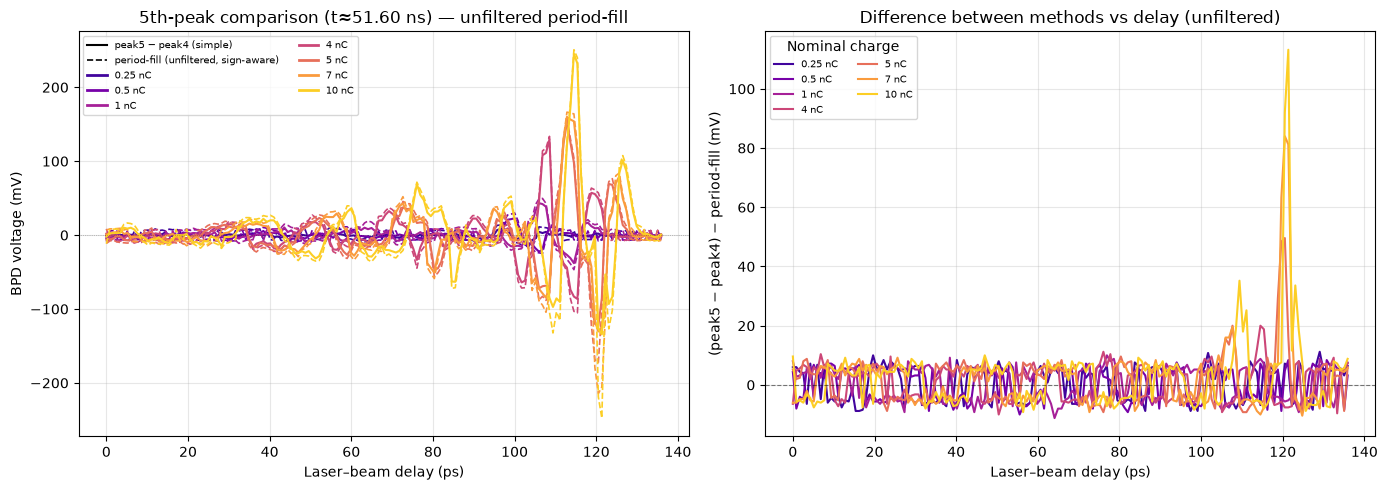

In [ ]:
# \u2500\u2500 2d.8 \u00b7 Validation: UNFILTERED period-fill vs (peak5\u2212peak4) simple removal \u2500
# Both methods, same 5th-peak window, no normalisation, sign-aware readout.
# Period-fill here uses the UNFILTERED residual (traces \u2212 before-only baseline),
# i.e. NO FFT low-pass, so the comparison isolates the windowing difference from
# the filter. Readout is the signed extremum (largest |value| keeping its sign)
# so negative EO excursions are captured, unlike a plain .max().
# Left:  per-delay values in mV \u2014 solid = peak5\u2212peak4, dashed = unfiltered period-fill.
# Right: difference (peak5\u2212peak4) \u2212 period-fill in mV vs delay.
from scipy.signal import find_peaks as _fp
from matplotlib.lines import Line2D

# Recompute 5th-peak window (same as cells 11 / 2d.5)
_rec_ref    = scans[-1]
_grand_mean = _rec_ref['traces_raw'].mean(axis=0)
_dt_ns      = _rec_ref['t_ns'][1] - _rec_ref['t_ns'][0]
_min_sep    = int(0.8 * T_LASER_NS / _dt_ns)
_peak_idxs, _ = _fp(_grand_mean, distance=_min_sep)
_pk5        = _peak_idxs[4]
_half_win   = int(0.3 * T_LASER_NS / _dt_ns)
_win5       = slice(max(0, _pk5 - _half_win),
                    min(len(_rec_ref['t_ns']), _pk5 + _half_win))
_t5_ns      = _rec_ref['t_ns'][_pk5]

def _signed_extremum(seg):
    """Largest |value| keeping its sign, per row (delay step)."""
    j = np.argmax(np.abs(seg), axis=1)
    return np.take_along_axis(seg, j[:, None], axis=1)[:, 0]

# Unfiltered period-fill residual in the 5th-peak window, sign-aware.
# Baseline reconstructed exactly as in reduce_bpd (before-window period only),
# but WITHOUT the fft_lowpass step.
for rec in scans:
    traces = rec['traces_raw']
    i0, i1, sl, sr = _period_fill_indices(rec['t_ns'], SIGNAL_START_NS, SIGNAL_END_NS)
    bl = traces.copy()
    bl[:, i0:i1] = traces[:, sl]                 # before-only baseline (matches reduce_bpd)
    res_unfilt = traces - bl                       # no FFT low-pass
    rec['res_pf_unfilt_peak5'] = _signed_extremum(res_unfilt[:, _win5])   # (steps,) V

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for rec, col in zip(scans, colors):
    simple = rec['bpd_peak5_max'] - rec['bpd_peak4_max']   # peak5 \u2212 peak4
    pf     = rec['res_pf_unfilt_peak5']
    axes[0].plot(rec['delay_ps'], MV * simple, color=col, lw=1.5, ls='-')
    axes[0].plot(rec['delay_ps'], MV * pf,     color=col, lw=1.2, ls='--')
    axes[1].plot(rec['delay_ps'], MV * (simple - pf), color=col, lw=1.5, label=rec['label'])

axes[0].axhline(0, color='k', lw=0.5, ls=':', alpha=0.4)
axes[0].set_xlabel('Laser\u2013beam delay (ps)')
axes[0].set_ylabel('BPD voltage (mV)')
axes[0].set_title(f'5th-peak comparison (t\u2248{_t5_ns:.2f} ns) \u2014 unfiltered period-fill')
_style_handles = [
    Line2D([0], [0], color='k', lw=1.5, ls='-',  label='peak5 \u2212 peak4 (simple)'),
    Line2D([0], [0], color='k', lw=1.2, ls='--', label='period-fill (unfiltered, sign-aware)'),
]
_charge_handles = [Line2D([0], [0], color=col, lw=2, label=rec['label'])
                   for rec, col in zip(scans, colors)]
axes[0].legend(handles=_style_handles + _charge_handles, fontsize=7, ncol=2)
axes[0].grid(True, alpha=0.3)

axes[1].axhline(0, color='k', lw=0.8, ls='--', alpha=0.5)
axes[1].set_xlabel('Laser\u2013beam delay (ps)')
axes[1].set_ylabel('(peak5 \u2212 peak4) \u2212 period-fill (mV)')
axes[1].set_title('Difference between methods vs delay (unfiltered)')
axes[1].legend(title='Nominal charge', fontsize=7, ncol=2)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Results/03g_baseline_validation.png', dpi=180, bbox_inches='tight')
plt.show()


In [ ]:
# ── 2d.4 · Export peak 4 and peak 5 max/min vs delay to CSV (one file per charge per peak)
import csv, os

os.makedirs('Results/peak_csvs', exist_ok=True)

for peak_num in [4, 5]:
    for rec in scans:
        label_safe = rec['label'].replace(' ', '').replace('/', '')
        fname = f'Results/peak_csvs/peak{peak_num}_{label_safe}.csv'
        with open(fname, 'w', newline='') as f:
            writer = csv.writer(f)
            writer.writerow(['delay_ps', 'min_mV', 'max_mV'])
            for d, mn, mx in zip(rec['delay_ps'],
                                  MV * rec[f'bpd_peak{peak_num}_min'],
                                  MV * rec[f'bpd_peak{peak_num}_max']):
                writer.writerow([f'{d:.4f}', f'{mn:.4f}', f'{mx:.4f}'])
        print(f'Saved {fname}')


Saved Results/peak_csvs/peak4_0.25nC.csv
Saved Results/peak_csvs/peak4_0.5nC.csv
Saved Results/peak_csvs/peak4_1nC.csv
Saved Results/peak_csvs/peak4_4nC.csv
Saved Results/peak_csvs/peak4_5nC.csv
Saved Results/peak_csvs/peak4_7nC.csv
Saved Results/peak_csvs/peak4_10nC.csv
Saved Results/peak_csvs/peak5_0.25nC.csv
Saved Results/peak_csvs/peak5_0.5nC.csv
Saved Results/peak_csvs/peak5_1nC.csv
Saved Results/peak_csvs/peak5_4nC.csv
Saved Results/peak_csvs/peak5_5nC.csv
Saved Results/peak_csvs/peak5_7nC.csv
Saved Results/peak_csvs/peak5_10nC.csv


In [ ]:
# ── 2d.5 · Combined CSV per charge level ─────────────────────────────────────
# One file per charge level; columns:
#   delay_ps | signed_amp_mV (period fill) |
#   peak5_max_mV (t=<5th-peak ns>) | peak5_min_mV |
#   peak4_max_mV (t=<4th-peak ns>) | peak4_min_mV
import csv as _csv, os as _os
from scipy.signal import find_peaks as _find_peaks

_os.makedirs('Results/combined_csvs', exist_ok=True)

# Recompute peak centre times from the 10 nC reference trace
_rec_ref    = scans[-1]
_grand_mean = _rec_ref['traces_raw'].mean(axis=0)
_dt_ns      = _rec_ref['t_ns'][1] - _rec_ref['t_ns'][0]
_min_sep    = int(0.8 * T_LASER_NS / _dt_ns)
_peak_idxs, _ = _find_peaks(_grand_mean, distance=_min_sep)

t_peak4_ns = _rec_ref['t_ns'][_peak_idxs[3]]
t_peak5_ns = _rec_ref['t_ns'][_peak_idxs[4]]

header = [
    'delay_ps',
    'signed_amp_mV',
    f'peak5_max_mV (t={t_peak5_ns:.2f} ns)',
    f'peak5_min_mV (t={t_peak5_ns:.2f} ns)',
    f'peak4_max_mV (t={t_peak4_ns:.2f} ns)',
    f'peak4_min_mV (t={t_peak4_ns:.2f} ns)',
]

for rec in scans:
    label_safe = rec['label'].replace(' ', '').replace('/', '')
    fname = f'Results/combined_csvs/{label_safe}.csv'
    with open(fname, 'w', newline='') as _f:
        writer = _csv.writer(_f)
        writer.writerow(header)
        for row in zip(
            rec['delay_ps'],
            MV * rec['signed_amp'],
            MV * rec['bpd_peak5_max'],
            MV * rec['bpd_peak5_min'],
            MV * rec['bpd_peak4_max'],
            MV * rec['bpd_peak4_min'],
        ):
            writer.writerow([f'{v:.4f}' for v in row])
    print(f'Saved {fname}  ({len(rec["delay_ps"])} rows)')

print(f'\nPeak times used in column headers:')
print(f'  4th peak: {t_peak4_ns:.2f} ns')
print(f'  5th peak: {t_peak5_ns:.2f} ns')


Saved Results/combined_csvs/0.25nC.csv  (160 rows)
Saved Results/combined_csvs/0.5nC.csv  (160 rows)
Saved Results/combined_csvs/1nC.csv  (160 rows)
Saved Results/combined_csvs/4nC.csv  (160 rows)
Saved Results/combined_csvs/5nC.csv  (160 rows)
Saved Results/combined_csvs/7nC.csv  (160 rows)
Saved Results/combined_csvs/10nC.csv  (160 rows)

Peak times used in column headers:
  4th peak: 39.28 ns
  5th peak: 51.60 ns


## 3 · Heatmaps over (laser delay, scope time)

Two views per scan:
- **Raw mean trace** vs delay — laser-train carrier is visible at $T = 12.3$ ns spacing.
- **Residual** (baseline-subtracted, LP-filtered) — the EO modulation is localized at the probe time and grows with charge.

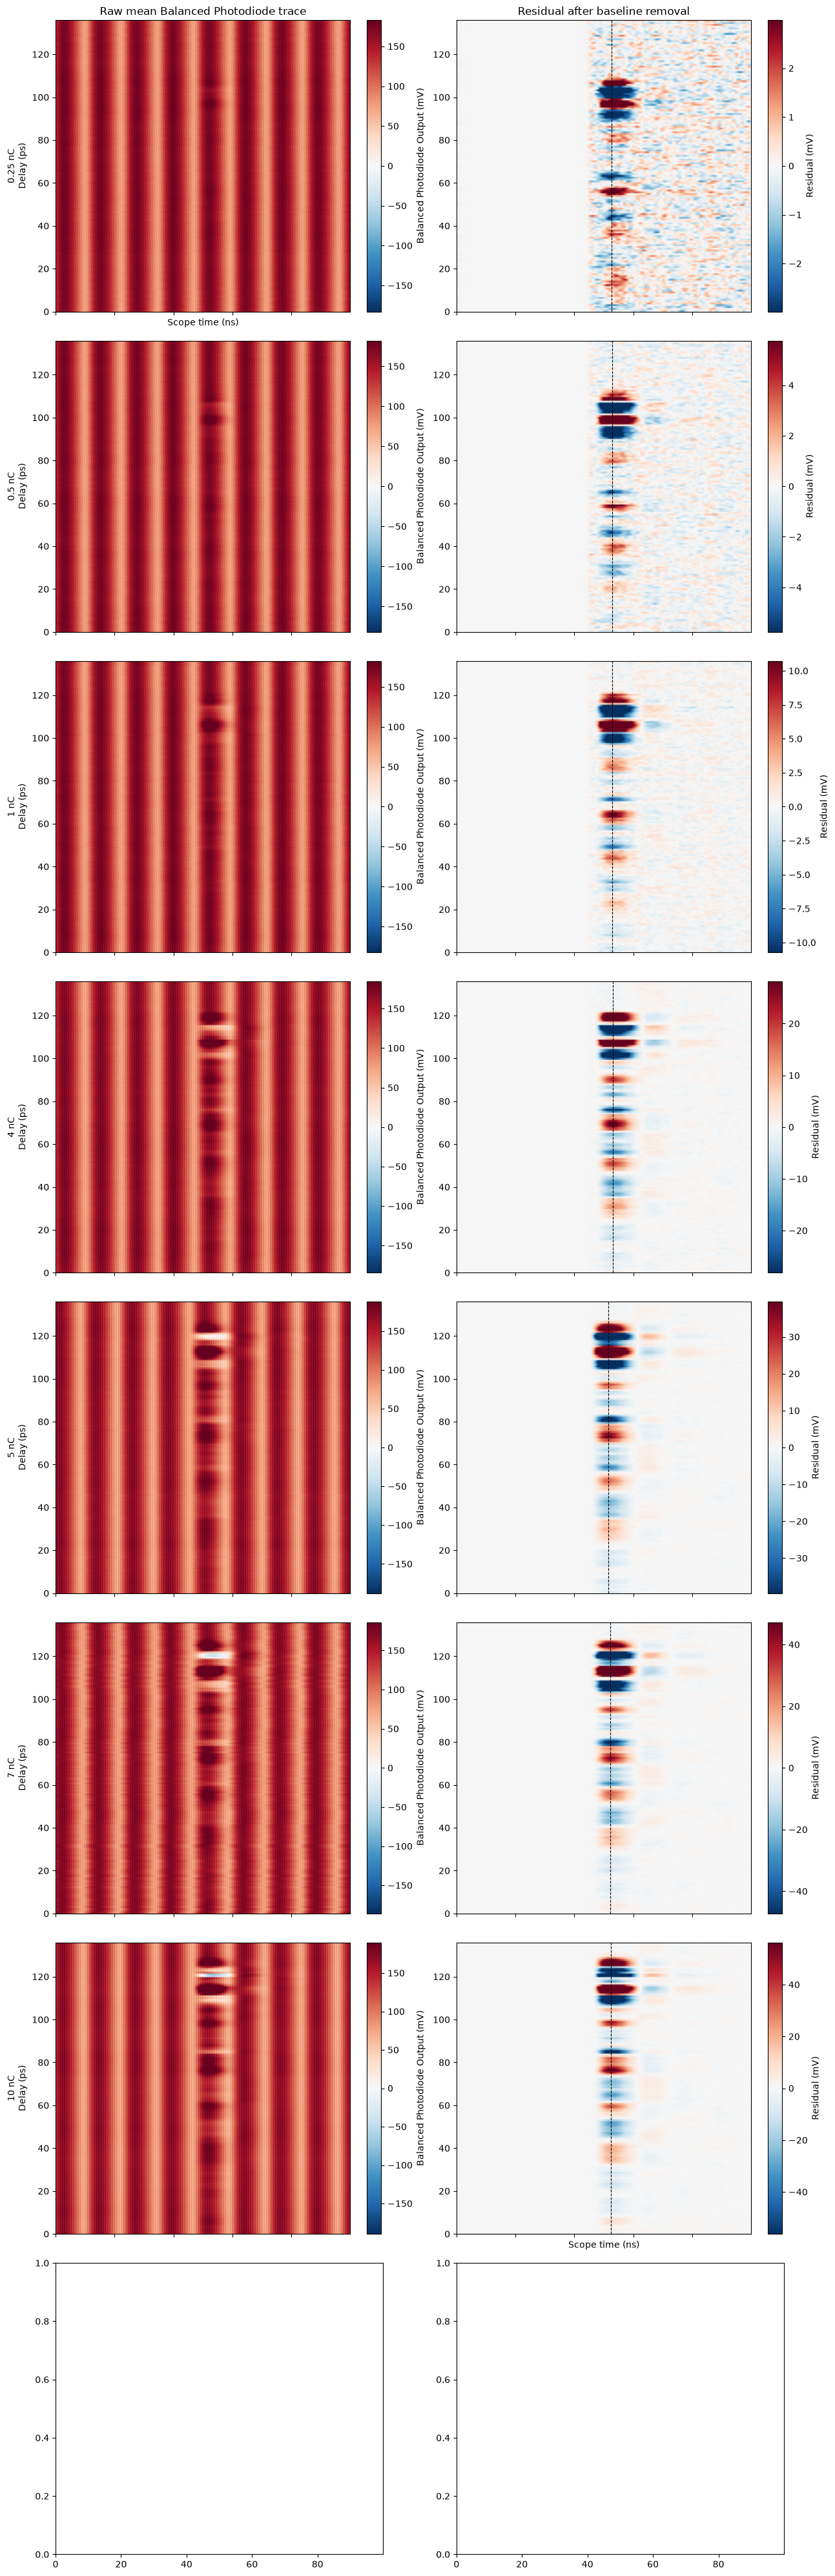

In [ ]:
fig, axes = plt.subplots(len(scans)+1, 2, figsize=(13, 5*len(scans)+5), sharex=True)
for row, (rec, col) in enumerate(zip(scans, colors)):
    t_ns = rec['t_ns']; dly = rec['delay_ps']
    # raw
    raw = MV * rec['traces_raw']
    vmax = np.percentile(np.abs(raw), 99)
    im0 = axes[row][0].imshow(raw, aspect='auto', origin='lower',
                              extent=[t_ns[0], t_ns[-1], dly[0], dly[-1]],
                              cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    axes[row][0].set_ylabel(f"{rec['label']}\nDelay (ps)")
    plt.colorbar(im0, ax=axes[row][0], fraction=0.05).set_label('Balanced Photodiode Output (mV)')
    # residual
    res = MV * rec['res']
    vmax = np.percentile(np.abs(res), 99)
    im1 = axes[row][1].imshow(res, aspect='auto', origin='lower',
                              extent=[t_ns[0], t_ns[-1], dly[0], dly[-1]],
                              cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    axes[row][1].axvline(t_ns[rec['tp']], color='k', ls='--', lw=0.8)
    plt.colorbar(im1, ax=axes[row][1], fraction=0.05).set_label('Residual (mV)')
    if row == 0:
        axes[row][0].set_title('Raw mean Balanced Photodiode trace');     axes[row][1].set_title('Residual after baseline removal')
axes[0][0].set_xlabel('Scope time (ns)');  axes[row][1].set_xlabel('Scope time (ns)')
plt.tight_layout(); plt.savefig('Results/heatmaps/04_BPD_heatmaps.png', dpi=160, bbox_inches='tight'); plt.show()

## 4 · ICT physical charge per shot

The integrating current transformer encodes the bunch charge in its baseline-corrected pulse area:
$$Q\,[\mathrm{nC}] = 0.8\,\Big|\!\int V_\text{ICT}\,dt\Big| = 0.8 \cdot \big(\!-\!\Sigma_\text{samples}\,V\big)\cdot \Delta t_\text{eff}$$
with $\Delta t_\text{eff} = 0.444$ ns/sample (calibrated from the nominal-charge fit in the standalone ICT notebook). Baseline is the mean of pre-pulse samples `[:700]` and post-pulse samples `[1300:]`; the pulse is negative, so the signed sum is flipped to yield a positive charge.

This section unfolds the structure inside each scan:

- **4a** Per-step ICT voltage traces — every trial overlaid, grand mean in bold.
- **4b** Charge across trials (per-step mean ± shot σ, plus drift summary).
- **4c** Per-shot charge distribution (1600 shots per scan) — boxplot + scatter.
- **4d** Charge linearity vs. operator-reported nominal.

A "trial" here = one phase step (10 shots averaged). Each scan has 160 trials = 1600 individual ICT shots.

In [ ]:
def ict_charge(ict, min_Q_nC=0.0):
    """Per-shot ICT charge in nC, with non-positive shots masked as dropouts.

    A "dropout" is a shot where the photoinjector failed to fire — the ICT
    integration window then contains only baseline ringing and the signed sum
    can land below zero. We mask Q ≤ min_Q_nC as NaN so per-step means and
    stds reflect only physically meaningful bunches.
    """
    bl = np.concatenate([ict[:, :, ICT_BL_PRE], ict[:, :, ICT_BL_POST]], axis=2).mean(axis=2)
    ictc = ict - bl[:, :, np.newaxis]
    raw_sum = -ictc.sum(axis=2)                                  # (steps, 10) V·samples
    Q_shot  = ICT_K * raw_sum * DT_ICT_NS                        # (steps, 10) nC

    dropout_mask = Q_shot <= min_Q_nC                            # True where the bunch failed
    Q_kept = np.where(dropout_mask, np.nan, Q_shot)

    per_step      = np.nanmean(Q_kept, axis=1)
    step_std      = np.nanstd (Q_kept, axis=1)
    shot_std_mean = np.nanmean(step_std)
    Q_mean        = np.nanmean(Q_kept)

    return {'per_shot':      Q_shot,            # raw (includes dropouts) — kept for reference plots
            'per_shot_kept': Q_kept,            # NaN where dropped
            'dropout_mask':  dropout_mask,
            'dropout_frac':  dropout_mask.mean(),
            'per_step':      per_step,
            'step_std':      step_std,
            'shot_std_mean': shot_std_mean,
            'Q_mean':        Q_mean,
            'ictc':          ictc}

for rec in scans:
    rec['ict'] = ict_charge(rec['ictwf'], min_Q_nC=0.0)

print(f"{'Scan':>8}  {'Q_meas (nC)':>12}  {'shot CV %':>10}  {'step CV %':>10}  "
      f"{'dropouts':>10}  {'Q_nom':>8}")
print('-' * 80)
for rec in scans:
    Qm      = rec['ict']['Q_mean']
    shot_cv = 100 * rec['ict']['shot_std_mean'] / Qm
    step_cv = 100 * np.nanstd(rec['ict']['per_step']) / Qm
    n_drop  = int(rec['ict']['dropout_mask'].sum())
    n_tot   = rec['ict']['dropout_mask'].size
    print(f"{rec['label']:>8}  {Qm:12.3f}  {shot_cv:10.1f}  {step_cv:10.1f}  "
          f"{n_drop:5d}/{n_tot:<4d}  {rec['Q_nom']:8.2f}")

    Scan   Q_meas (nC)   shot CV %   step CV %    dropouts     Q_nom
--------------------------------------------------------------------------------
 0.25 nC         0.346        12.0         5.0      0/1600      0.25
  0.5 nC         0.668         8.5         4.1      0/1600      0.50
    1 nC         1.141         6.9         3.5      6/1600      1.00
    4 nC         4.726         6.8         3.7      2/1600      4.00
    5 nC         5.676         5.5         2.7      7/1600      5.00
    7 nC         6.958         6.5         3.6      1/1600      7.00
   10 nC        10.095         6.9         3.7      6/1600     10.00


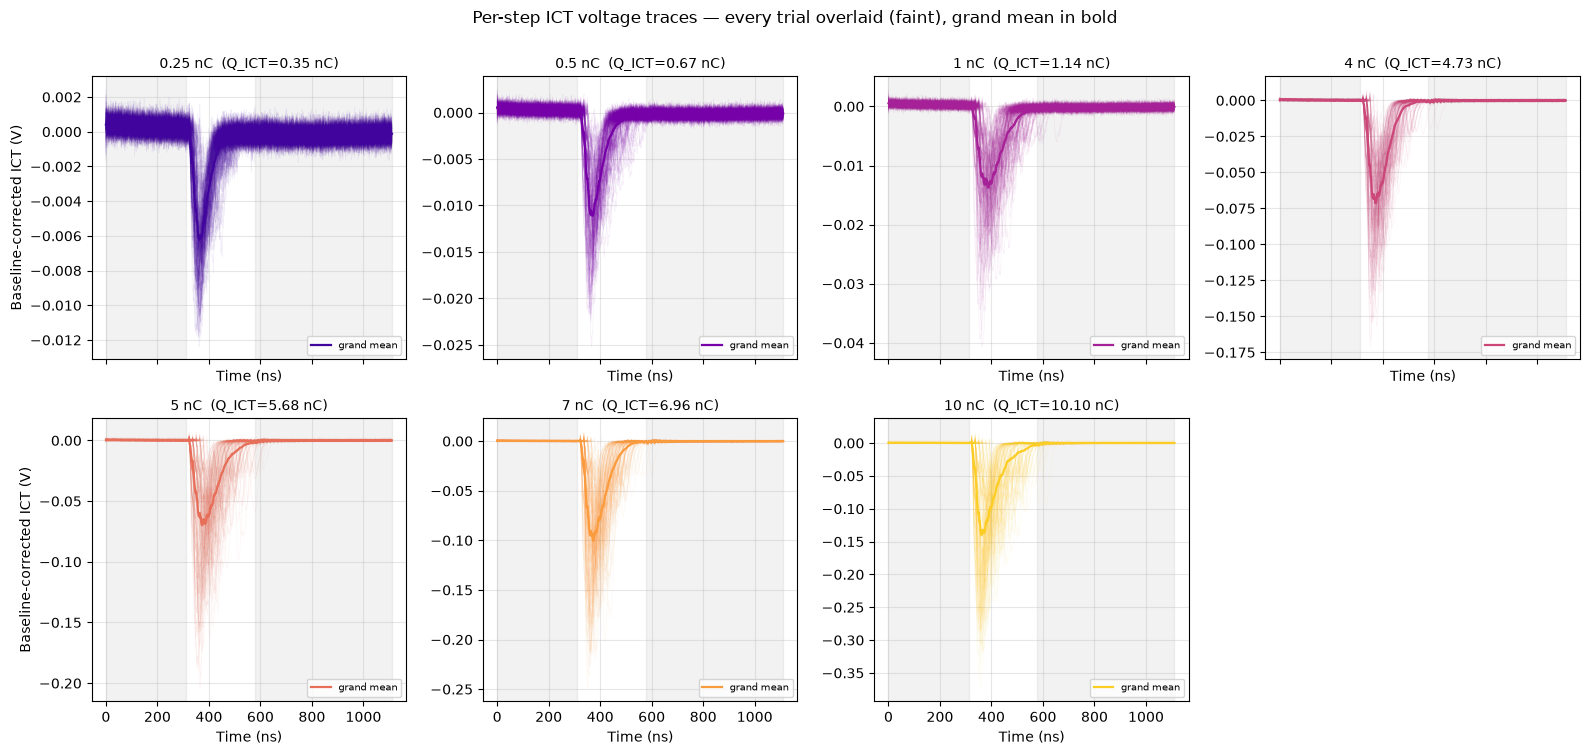

In [ ]:
# ── 4a · ICT voltage traces — every per-step trial overlaid, grand mean in bold ──
# For each scan, every phase step contributes one 10-shot-averaged ICT pulse.
# Plot all 160 step-mean traces (faint), overlay the per-scan grand mean (thick),
# and shade the baseline windows. Time axis is converted to ns via Δt_eff.

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), sharex=True)
ax_list   = axes.flatten()
for ax, rec, col in zip(ax_list, scans, colors):
    ictc       = rec['ict']['ictc']                        # (steps, 10, 2502)
    step_mean  = ictc.mean(axis=1)                          # (steps, 2502)
    grand_mean = ictc.mean(axis=(0, 1))                     # (2502,)
    t_ict_ns   = np.arange(ictc.shape[2]) * DT_ICT_NS
    for s in range(step_mean.shape[0]):
        ax.plot(t_ict_ns, step_mean[s], color=col, alpha=0.06, lw=0.5)
    ax.plot(t_ict_ns, grand_mean, color=col, lw=1.6, label='grand mean')
    ax.axvspan(t_ict_ns[0],   t_ict_ns[700],  alpha=0.10, color='gray')
    ax.axvspan(t_ict_ns[1300], t_ict_ns[-1],   alpha=0.10, color='gray')
    ax.set_title(f"{rec['label']}  (Q_ICT={rec['ict']['Q_mean']:.2f} nC)", fontsize=10)
    ax.set_xlabel('Time (ns)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc='lower right')
ax_list[0].set_ylabel('Baseline-corrected ICT (V)')
ax_list[4].set_ylabel('Baseline-corrected ICT (V)')
# hide unused panels (we have 7 scans, 8 panels)
for k in range(len(scans), len(ax_list)):
    ax_list[k].set_visible(False)
plt.suptitle('Per-step ICT voltage traces — every trial overlaid (faint), grand mean in bold', y=1.00)
plt.tight_layout()
plt.savefig('Results/05a_ICT_traces_per_step.png', dpi=170, bbox_inches='tight')
plt.show()

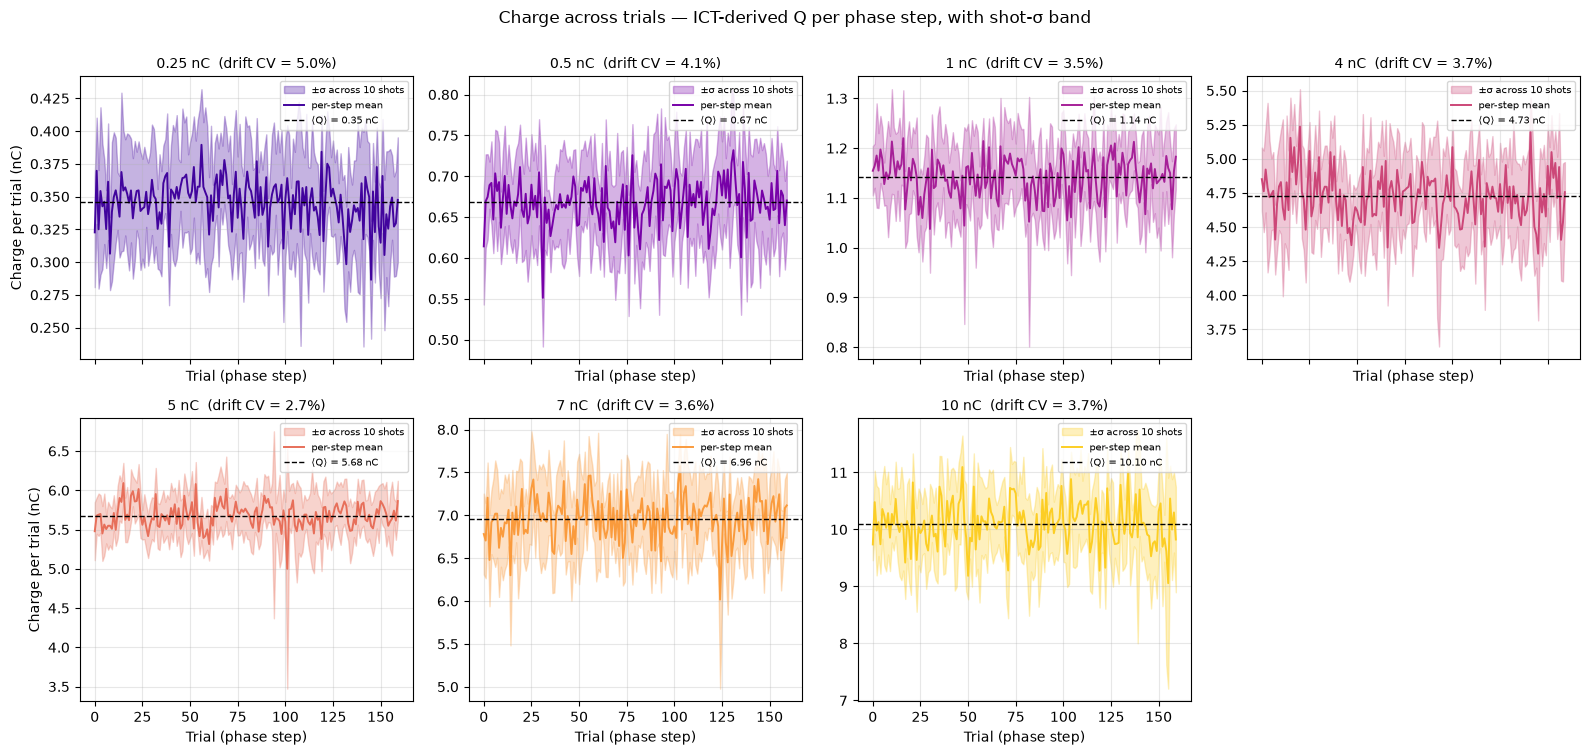

In [ ]:
# ── 4b · Charge across trials — per-step Q with shot-σ band ──────────────────
# x-axis = trial index (= phase step), y-axis = ICT-derived charge in nC.
# Per-step mean is the central line; ±1σ across the 10 shots is the shaded band.
# A dashed horizontal line marks the per-scan grand mean Q_ICT.

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), sharex=True)
ax_list = axes.flatten()
for ax, rec, col in zip(ax_list, scans, colors):
    step_idx = np.arange(len(rec['ict']['per_step']))
    mu       = rec['ict']['per_step']
    sd       = rec['ict']['step_std']
    Qbar     = rec['ict']['Q_mean']
    ax.fill_between(step_idx, mu - sd, mu + sd, color=col, alpha=0.30, label='±σ across 10 shots')
    ax.plot(step_idx, mu, color=col, lw=1.4, label='per-step mean')
    ax.axhline(Qbar, ls='--', color='k', lw=1, label=f'⟨Q⟩ = {Qbar:.2f} nC')
    drift_cv = 100 * mu.std() / Qbar
    ax.set_title(f"{rec['label']}  (drift CV = {drift_cv:.1f}%)", fontsize=10)
    ax.set_xlabel('Trial (phase step)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc='upper right')
ax_list[0].set_ylabel('Charge per trial (nC)')
ax_list[4].set_ylabel('Charge per trial (nC)')
for k in range(len(scans), len(ax_list)):
    ax_list[k].set_visible(False)
plt.suptitle('Charge across trials — ICT-derived Q per phase step, with shot-σ band', y=1.00)
plt.tight_layout()
plt.savefig('Results/05b_charge_vs_trial.png', dpi=170, bbox_inches='tight')
plt.show()

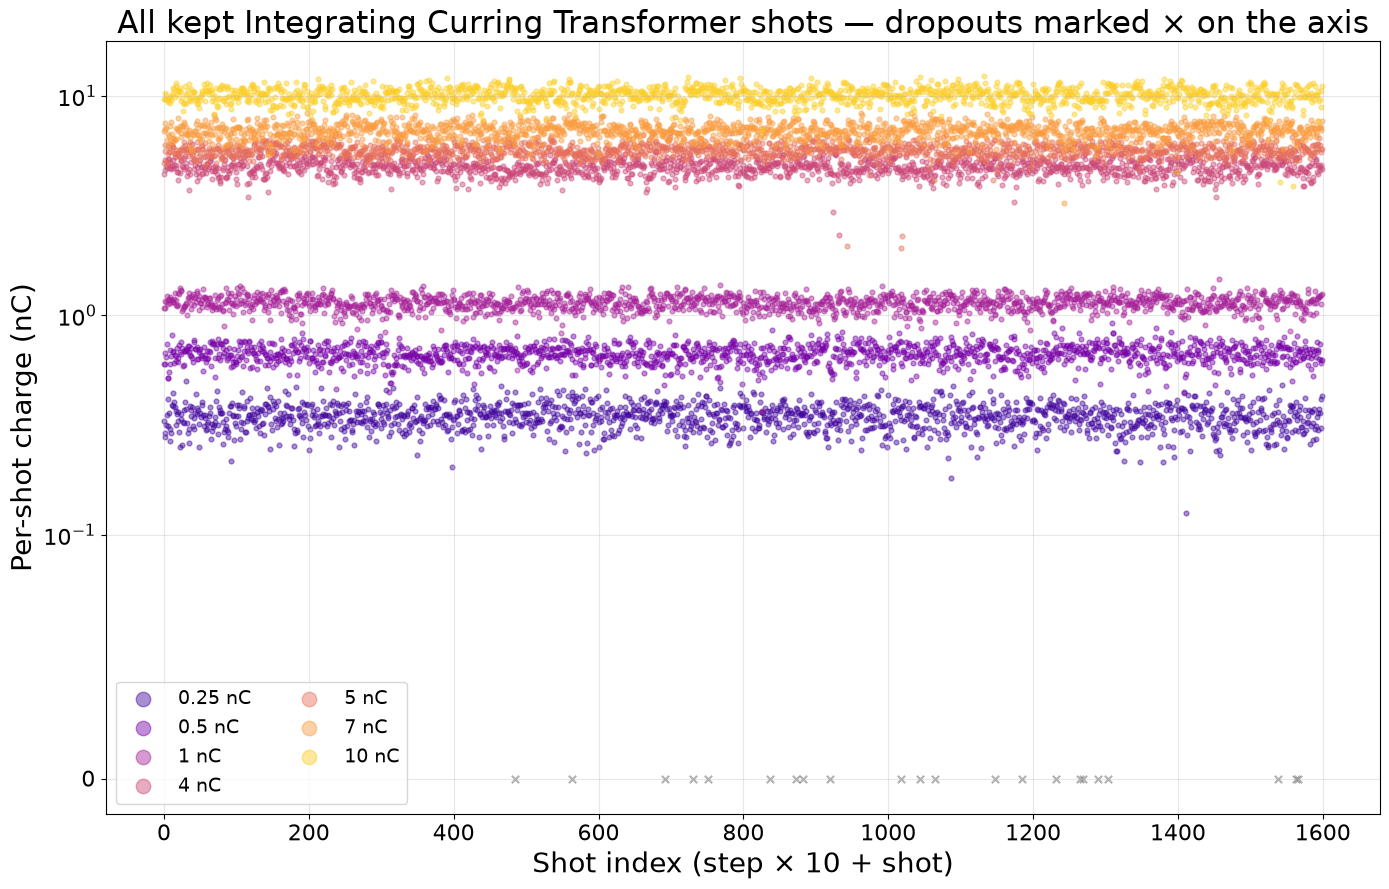


    Scan    mean Q    median    shot σ       min       max    CV %   drop %
--------------------------------------------------------------------------------
 0.25 nC     0.346     0.347     0.046     0.126     0.502    13.4      0.0
  0.5 nC     0.668     0.668     0.065     0.445     0.924     9.7      0.0
    1 nC     1.141     1.145     0.092     0.368     1.460     8.1      0.4
    4 nC     4.726     4.728     0.376     2.315     6.073     8.0      0.1
    5 nC     5.676     5.682     0.374     2.036     6.766     6.6      0.4
    7 nC     6.958     6.983     0.531     3.269     8.391     7.6      0.1
   10 nC    10.095    10.108     0.821     3.869    12.276     8.1      0.4


In [ ]:
# ── 4c · Per-shot charge distribution — dropouts filtered out ────────────────
# Scatter of every kept shot, color-coded by scan, vs global shot index.
# Greyed crosses mark the dropouts (Q ≤ 0) for reference.

fig, ax = plt.subplots(figsize=(14, 9))

for rec, col in zip(scans, colors):
    Q_raw  = rec['ict']['per_shot'].ravel()
    shot_idx = np.arange(len(Q_raw))
    drop_mask = rec['ict']['dropout_mask'].ravel()
    ax.scatter(shot_idx[~drop_mask], Q_raw[~drop_mask],
               s=12, alpha=0.45, color=col, label=rec['label'])
    ax.scatter(shot_idx[drop_mask], np.zeros(drop_mask.sum()),
               marker='x', s=28, color='gray', alpha=0.6)
ax.set_xlabel('Shot index (step × 10 + shot)', fontsize=20)
ax.set_ylabel('Per-shot charge (nC)', fontsize=20)
ax.set_title('All kept Integrating Curring Transformer shots — dropouts marked × on the axis', fontsize=22)
ax.set_yscale('symlog', linthresh=0.1)
ax.tick_params(axis='both', which='major', labelsize=16)
ax.grid(True, alpha=0.3, which='both')
ax.legend(fontsize=14, ncol=2, markerscale=3.0)

plt.tight_layout()
plt.savefig('Results/05c_per_shot_charge.png', dpi=300, bbox_inches='tight')
plt.show()

# Compact stats table — kept shots only
print(f"\n{'Scan':>8}  {'mean Q':>8}  {'median':>8}  {'shot σ':>8}  {'min':>8}  {'max':>8}"
      f"  {'CV %':>6}  {'drop %':>7}")
print('-' * 80)
for rec in scans:
    qs = rec['ict']['per_shot_kept'].ravel()
    qs = qs[~np.isnan(qs)]
    cv = 100 * qs.std() / qs.mean()
    drop_pct = 100 * rec['ict']['dropout_frac']
    print(f"{rec['label']:>8}  {qs.mean():8.3f}  {np.median(qs):8.3f}  {qs.std():8.3f}  "
          f"{qs.min():8.3f}  {qs.max():8.3f}  {cv:6.1f}  {drop_pct:7.1f}")

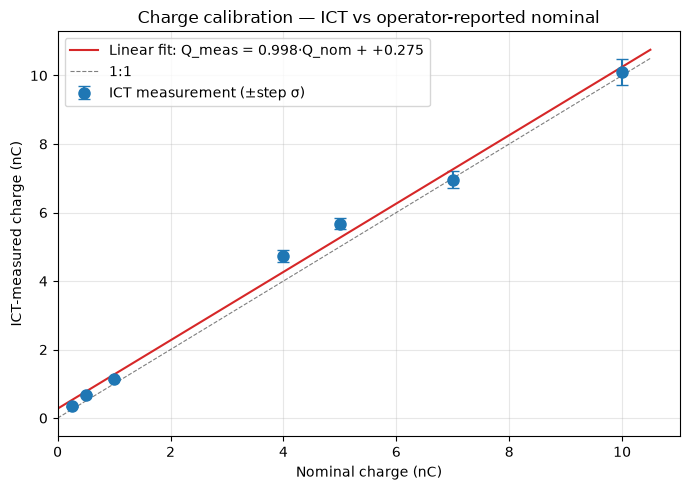

In [ ]:
# ── 4d · Charge linearity check — measured Q vs nominal Q ─────────────────
Q_nom_arr  = np.array([rec['Q_nom']        for rec in scans])
Q_meas_arr = np.array([rec['ict']['Q_mean'] for rec in scans])
Q_err_arr  = np.array([rec['ict']['per_step'].std() for rec in scans])

p_fit      = np.polyfit(Q_nom_arr, Q_meas_arr, 1)
Q_fit_line = np.poly1d(p_fit)
x_line     = np.linspace(0, Q_nom_arr.max()*1.05, 100)

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(Q_nom_arr, Q_meas_arr, yerr=Q_err_arr, fmt='o', ms=8, capsize=4,
            color='C0', label='ICT measurement (±step σ)')
ax.plot(x_line, Q_fit_line(x_line), 'C3-', lw=1.5,
        label=f'Linear fit: Q_meas = {p_fit[0]:.3f}·Q_nom + {p_fit[1]:+.3f}')
ax.plot(x_line, x_line, 'k--', lw=0.8, alpha=0.5, label='1:1')
ax.set_xlabel('Nominal charge (nC)'); ax.set_ylabel('ICT-measured charge (nC)')
ax.set_title('Charge calibration — ICT vs operator-reported nominal')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_xlim(0)
plt.tight_layout()
plt.savefig('Results/06_charge_calibration.png', dpi=180, bbox_inches='tight')
plt.show()

## 5 · BPD response vs. measured charge

Three BPD metrics, all plotted against the ICT-measured charge $Q_\text{ICT}$:
- peak signed amplitude $|V_\text{sig}|_\text{max}$
- **global peak-to-peak** of the signed amplitude across the full delay scan,
  $V_\text{p2p}^\text{global} = \max_\tau V_\text{sig}(\tau) - \min_\tau V_\text{sig}(\tau)$
  — captures the full positive→negative swing of the EO response as the laser delay sweeps through the THz pulse zero-crossing.
- integrated $\int |V_\text{sig}|\,d\tau$ over the scan

We fit a linear model $V = \kappa\,Q$ for each (origin-fixed). Slope $\kappa$ is the sensor sensitivity in V/nC (or V·ps/nC for the integral).

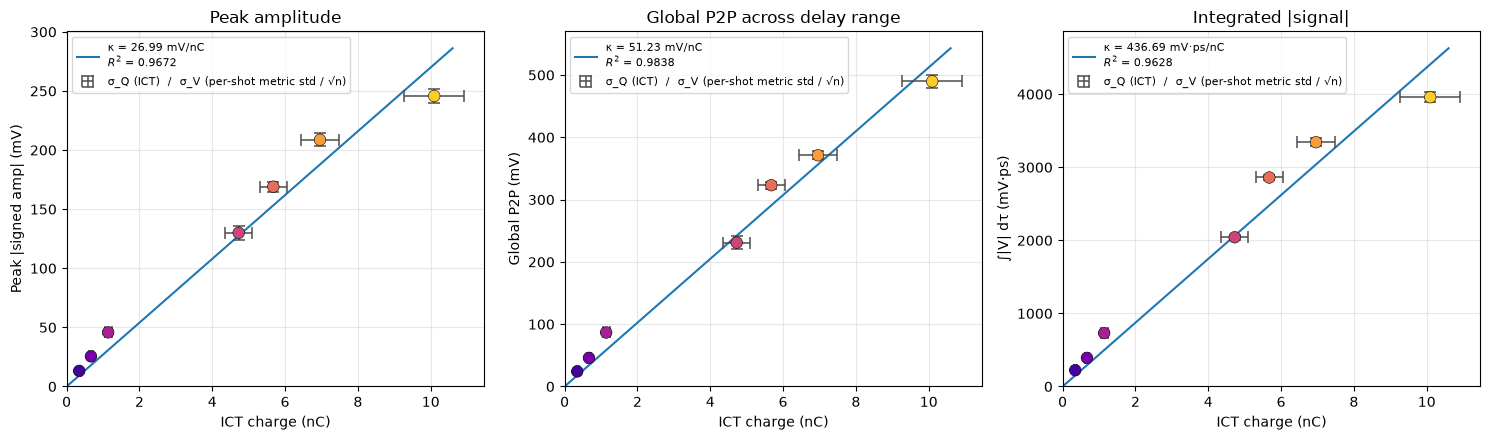


Origin-fit slopes and R²:
  peak |signed amp|     :  κ_amp  =  26.994 mV/nC      R² = 0.9672
  global P2P (max-min)  :  κ_p2p  =  51.229 mV/nC      R² = 0.9838
  integrated |V|        :  κ_int  = 436.689 mV·ps/nC   R² = 0.9628

Empirical per-shot metric std / √n_shots (vertical errorbars):
    scan    σ_amp (mV)    σ_p2p (mV)   σ_int (mV·ps)
  0.25 nC        0.6369        1.1694          3.7184
  0.5 nC        0.4349        1.2287          7.0278
    1 nC        1.1146        1.3510          9.5526
    4 nC        5.7696       11.0653         34.1736
    5 nC        4.3526        5.8305         39.8299
    7 nC        5.4338        6.1235         54.0141
   10 nC        5.8710       10.9296         66.7259


In [ ]:
amp_peak = np.array([s['amp_peak']  for s in summary])
# Global P2P = full swing of the signed amplitude across the entire delay scan
p2p_global = np.array([rec['signed_amp'].max() - rec['signed_amp'].min() for rec in scans])
integ      = np.array([s['integ_abs'] for s in summary])
Q_meas     = Q_meas_arr.copy()

# Horizontal error bar for each per-scan point = per-shot σ across all kept
# ICT shots in the scan (the actual scatter of charge during that scan).
Q_xerr = np.array([
    np.nanstd(rec['ict']['per_shot_kept'].ravel()) for rec in scans
])

# Vertical error bar = empirical std-of-mean of the metric across the n_shots
# per-shot realizations (computed in reduce_bpd). This captures every noise
# source at once — detector electronics, laser/timing jitter, ICT charge
# fluctuations, real bunch-to-bunch envelope variations.
amp_yerr   = np.array([rec['amp_peak_err']   for rec in scans])
p2p_yerr   = np.array([rec['p2p_global_err'] for rec in scans])
integ_yerr = np.array([rec['integ_abs_err']  for rec in scans])

def origin_slope(x, y):
    return (x*y).sum() / (x*x).sum()

def r_squared(x, y, k):
    """R² for the origin-fixed model y = k·x, using the standard SS_tot = Σ(y-ȳ)²."""
    y_hat   = k * x
    ss_res  = np.sum((y - y_hat) ** 2)
    ss_tot  = np.sum((y - y.mean()) ** 2)
    return 1.0 - ss_res / ss_tot

k_amp  = origin_slope(Q_meas, amp_peak)
k_p2pg = origin_slope(Q_meas, p2p_global)
k_int  = origin_slope(Q_meas, integ)

r2_amp  = r_squared(Q_meas, amp_peak,   k_amp )
r2_p2pg = r_squared(Q_meas, p2p_global, k_p2pg)
r2_int  = r_squared(Q_meas, integ,      k_int )

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (y, yerr, k, r2, ylab, ttl, scl) in zip(
    axes,
    [(amp_peak,   amp_yerr,   k_amp,  r2_amp,  'Peak |signed amp| (mV)',  'Peak amplitude',                MV),
     (p2p_global, p2p_yerr,   k_p2pg, r2_p2pg, 'Global P2P (mV)',          'Global P2P across delay range', MV),
     (integ,      integ_yerr, k_int,  r2_int,  '∫|V| dτ (mV·ps)',           'Integrated |signal|',           MV)]):
    # xerr = ICT per-shot σ_Q;  yerr = empirical per-shot metric std / √n_shots.
    ax.errorbar(Q_meas, scl*y, xerr=Q_xerr, yerr=scl*yerr, fmt='none',
                ecolor='0.3', elinewidth=1.1, capsize=4, capthick=1.1,
                zorder=4, label='σ_Q (ICT)  /  σ_V (per-shot metric std / √n)')
    ax.scatter(Q_meas, scl*y, s=70, c=colors, edgecolor='k', linewidth=0.4,
               zorder=5)
    xline = np.linspace(0, Q_meas.max()*1.05, 100)
    unit  = ylab.split("(")[1][:-1]
    ax.plot(xline, scl*k*xline, 'C0-', lw=1.5,
            label=f'κ = {scl*k:.2f} {unit}/nC\n$R^2$ = {r2:.4f}')
    ax.set_xlabel('ICT charge (nC)'); ax.set_ylabel(ylab)
    ax.set_title(ttl); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_xlim(0); ax.set_ylim(bottom=0)
plt.tight_layout(); plt.savefig('Results/07_BPD_vs_charge.png', dpi=400, bbox_inches='tight'); plt.show()

# Stash the global P2P back into summary so the downstream summary table picks it up
for s, p in zip(summary, p2p_global):
    s['p2p_global'] = p

k_p2p = k_p2pg  # keep the downstream variable name consistent

print(f'\nOrigin-fit slopes and R²:')
print(f'  peak |signed amp|     :  κ_amp  = {MV*k_amp :7.3f} mV/nC      R² = {r2_amp :.4f}')
print(f'  global P2P (max-min)  :  κ_p2p  = {MV*k_p2pg:7.3f} mV/nC      R² = {r2_p2pg:.4f}')
print(f'  integrated |V|        :  κ_int  = {MV*k_int :7.3f} mV·ps/nC   R² = {r2_int :.4f}')
print(f'\nEmpirical per-shot metric std / √n_shots (vertical errorbars):')
print(f'{"scan":>8}  {"σ_amp (mV)":>12}  {"σ_p2p (mV)":>12}  {"σ_int (mV·ps)":>14}')
for rec, sa, sp, si in zip(scans, amp_yerr, p2p_yerr, integ_yerr):
    print(f'  {rec["label"]:>6}  {MV*sa:>12.4f}  {MV*sp:>12.4f}  {MV*si:>14.4f}')

### 5b · Per-shot ICT ↔ BPD correlation

The per-scan fits above use one (Q, V) point per scan — 7 points total. The per-shot view is finer: each shot is one trigger event at one delay, with paired ICT charge $Q_\text{shot}$ and BPD signed amplitude $V_\text{shot}$ at the probe time of that shot's individual trace.

Since $V_\text{shot}$ depends on the laser–THz delay (the EO signature is bipolar), pooling across all 11,200 shots would mix delay variation into the Q scatter. To isolate the Q dependence we restrict the correlation to **each scan's EO-peak delay step** — the phase step where $|V_\text{step}|$ is maximum, where $\partial V/\partial Q$ is largest and the SNR is best. That gives 10 shots × 7 scans = **70 paired points** (dropouts excluded).

This is a *true shot-by-shot* test of whether the BPD response tracks the per-shot bunch charge, not just the per-scan average.

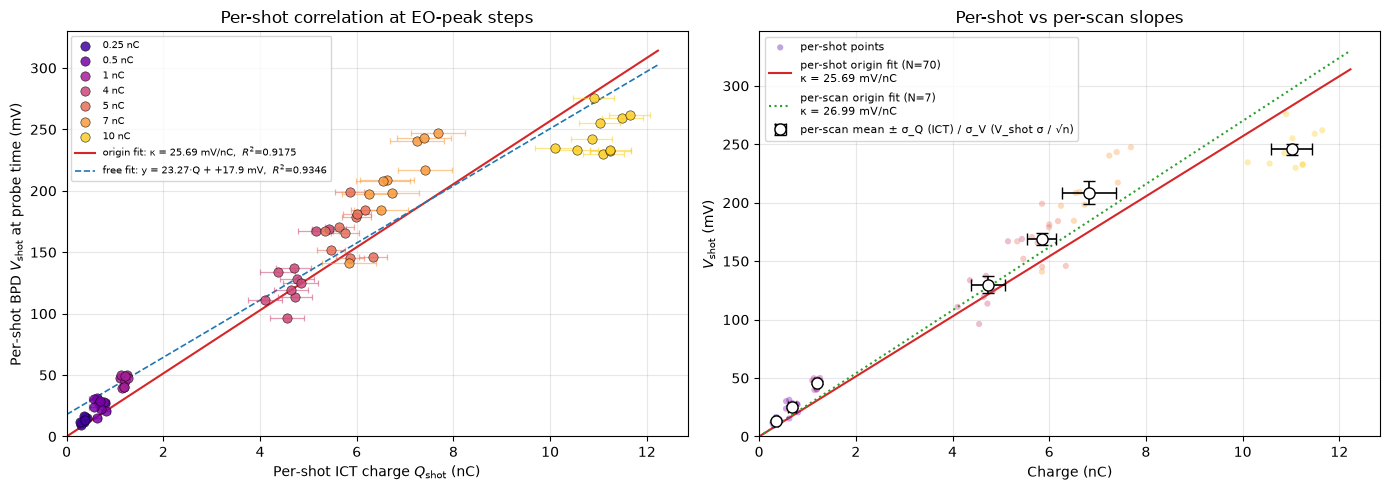


Per-shot correlation at each scan's EO-peak step (dropouts excluded):
    Scan  peak_step    τ (ps)   V_step (mV)   V_shot μ   V_shot σ   σ_mean=σ/√n     n
------------------------------------------------------------------------------------------
 0.25 nC        121    103.42        -13.21      13.21       2.14         0.676    10
  0.5 nC        117    100.00         25.52      25.52       4.65         1.471    10
    1 nC        124    105.98         45.83      45.83       3.92         1.241    10
    4 nC        127    108.55        130.01     130.01      22.06         6.976    10
    5 nC        141    120.51       -169.03     169.03      16.73         5.290    10
    7 nC        141    120.51       -208.71     208.71      30.28         9.574    10
   10 nC        134    114.53        245.76     245.76      15.21         4.810    10

Pooled per-shot linear fits  (N = 70):
  Pearson r            = 0.9667
  origin-fixed κ       =  25.685 mV/nC    R² = 0.9175
  free-intercept slope =

In [ ]:
# ── 5b · Per-shot BPD reduction and per-shot ↔ per-shot Q correlation ──────

# reduce_bpd (cell 5) already produced rec['signed_amp_ps'] of shape
# (steps, n_shots) — the per-shot baseline-corrected, FFT-LP-filtered
# signed amplitude at the probe time. Reuse it instead of recomputing.

# Pair per-shot V_shot with per-shot Q_shot at each scan's EO-peak step.
V_peak_shots, Q_peak_shots, Q_peak_xerr = [], [], []
labels_per_pt, colors_per_pt = [], []
peak_step_info = []

for rec, col in zip(scans, colors):
    V_shot = rec['signed_amp_ps']                    # (steps, n_shots) V

    # Pick the step where |V_step_mean| is maximum — same one used by 'amp_peak'
    step_mean = rec['signed_amp']
    peak_step = int(np.argmax(np.abs(step_mean)))
    sign      = np.sign(step_mean[peak_step]) or 1.0

    V_s = sign * V_shot[peak_step, :]                # flip sign so V scales positive with Q
    Q_s = rec['ict']['per_shot_kept'][peak_step, :]  # NaN for dropout shots
    keep = ~np.isnan(Q_s)

    xerr_step = float(np.nanstd(Q_s[keep])) if keep.any() else 0.0

    V_peak_shots.append(V_s[keep])
    Q_peak_shots.append(Q_s[keep])
    Q_peak_xerr .append(np.full(keep.sum(), xerr_step))
    labels_per_pt.extend([rec['label']] * keep.sum())
    colors_per_pt.extend([col] * keep.sum())
    peak_step_info.append({
        'label':     rec['label'],
        'peak_step': peak_step,
        'peak_dly':  rec['delay_ps'][peak_step],
        'V_step':    step_mean[peak_step],
        'V_shot_μ':  np.nanmean(V_s[keep]),
        'V_shot_σ':  np.nanstd (V_s[keep]),
        'n_kept':    int(keep.sum()),
    })

Q_all     = np.concatenate(Q_peak_shots)
V_all     = np.concatenate(V_peak_shots)
Q_xerr_all = np.concatenate(Q_peak_xerr)

# Linear fits — both origin-fixed and free-intercept
k_shot   = origin_slope(Q_all, V_all)
r2_shot  = r_squared   (Q_all, V_all, k_shot)
m_free, b_free = np.polyfit(Q_all, V_all, 1)
y_hat_free = m_free * Q_all + b_free
r2_free    = 1 - np.sum((V_all - y_hat_free)**2) / np.sum((V_all - V_all.mean())**2)
r_pear     = np.corrcoef(Q_all, V_all)[0, 1]

# ── Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: per-shot scatter at each scan's EO-peak step. The scatter of the
# points themselves visualizes the shot-to-shot variation; only xerr is
# shown (ICT charge σ within this step).
for Qs, Vs, Xe, col, info in zip(Q_peak_shots, V_peak_shots, Q_peak_xerr,
                                  colors, peak_step_info):
    axes[0].errorbar(Qs, MV*Vs, xerr=Xe, fmt='none',
                     ecolor=col, elinewidth=0.9, capsize=2.5, capthick=0.9,
                     alpha=0.55, zorder=3)
    axes[0].scatter(Qs, MV*Vs, s=45, color=col, edgecolor='k', linewidth=0.4,
                    label=f"{info['label']} ",
                    zorder=4, alpha=0.85)
xline = np.linspace(0, Q_all.max()*1.05, 200)
axes[0].plot(xline, MV*k_shot*xline,         'C3-',  lw=1.5,
             label=f'origin fit: κ = {MV*k_shot:.2f} mV/nC,  $R^2$={r2_shot:.4f}')
axes[0].plot(xline, MV*(m_free*xline+b_free), 'C0--', lw=1.2,
             label=f'free fit: y = {MV*m_free:.2f}·Q + {MV*b_free:+.1f} mV,  $R^2$={r2_free:.4f}')
axes[0].set_xlabel('Per-shot ICT charge $Q_\\text{shot}$ (nC)')
axes[0].set_ylabel(r'Per-shot BPD $V_\text{shot}$ at probe time (mV)')
axes[0].set_title(f'Per-shot correlation at EO-peak steps')
axes[0].legend(fontsize=7, loc='upper left'); axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0); axes[0].set_ylim(bottom=0)

# Right: per-scan means overlay vs per-shot cloud — compare slopes.
#   yerr on per-scan mean = empirical V_shot σ / √n_kept   (std of the mean,
#   from the actual within-scan scatter of per-shot V at the EO-peak step).
axes[1].scatter(Q_all, MV*V_all, s=20, c=colors_per_pt, alpha=0.35,
                edgecolor='none', label='per-shot points', zorder=3)
mu_Q = np.array([np.nanmean(Qs) for Qs in Q_peak_shots])
mu_V = np.array([np.nanmean(Vs) for Vs in V_peak_shots])
sd_Q = np.array([np.nanstd (Qs) for Qs in Q_peak_shots])
sd_V = np.array([info['V_shot_σ'] / np.sqrt(max(info['n_kept'], 1))
                  for info in peak_step_info])
axes[1].errorbar(mu_Q, MV*mu_V, xerr=sd_Q, yerr=MV*sd_V, fmt='o', ms=8,
                 color='k', mfc='white', capsize=4, lw=1.2,
                 label='per-scan mean ± σ_Q (ICT) / σ_V (V_shot σ / √n)', zorder=5)
axes[1].plot(xline, MV*k_shot*xline, 'C3-', lw=1.5,
             label=f'per-shot origin fit (N={len(Q_all)})\nκ = {MV*k_shot:.2f} mV/nC')
axes[1].plot(xline, MV*k_amp *xline, 'C2:', lw=1.5,
             label=f'per-scan origin fit (N=7)\nκ = {MV*k_amp:.2f} mV/nC')
axes[1].set_xlabel('Charge (nC)'); axes[1].set_ylabel(r'$V_\text{shot}$ (mV)')
axes[1].set_title('Per-shot vs per-scan slopes')
axes[1].legend(fontsize=8, loc='upper left'); axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(0); axes[1].set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('Results/07b_per_shot_correlation.png', dpi=400, bbox_inches='tight')
plt.show()

# Console summary
print(f'\nPer-shot correlation at each scan\'s EO-peak step (dropouts excluded):')
print(f'{"Scan":>8}  {"peak_step":>9}  {"τ (ps)":>8}  {"V_step (mV)":>12}  '
      f'{"V_shot μ":>9}  {"V_shot σ":>9}  {"σ_mean=σ/√n":>12}  {"n":>4}')
print('-' * 90)
for info in peak_step_info:
    sem = info['V_shot_σ'] / np.sqrt(max(info['n_kept'], 1))
    print(f"{info['label']:>8}  {info['peak_step']:>9d}  {info['peak_dly']:>8.2f}  "
          f"{MV*info['V_step']:>12.2f}  {MV*info['V_shot_μ']:>9.2f}  "
          f"{MV*info['V_shot_σ']:>9.2f}  {MV*sem:>12.3f}  {info['n_kept']:>4d}")

print(f'\nPooled per-shot linear fits  (N = {len(Q_all)}):')
print(f'  Pearson r            = {r_pear:.4f}')
print(f'  origin-fixed κ       = {MV*k_shot:7.3f} mV/nC    R² = {r2_shot:.4f}')
print(f'  free-intercept slope = {MV*m_free:7.3f} mV/nC    intercept = {MV*b_free:+.2f} mV    R² = {r2_free:.4f}')
print(f'\nCompare per-scan slope (N=7, from 5a above) : κ_amp = {MV*k_amp:.3f} mV/nC,  R² = {r2_amp:.4f}')

### 5c · Space-charge bunch-lengthening test — width and HF-falloff vs Q

The per-shot fit in 5b shows κ ≈ 25 mV/nC tracking individual shots, with the **10 nC point sitting noticeably below the trend established by 4–7 nC**. The Lorentz-model section (6 below) predicts strict linearity in Q for a fixed bunch shape, so any sub-linear rolloff has to come from a *shape* effect — most plausibly **space-charge-induced bunch lengthening** at high charge.

At AWA (γ ≈ 117), longitudinal space-charge forces lengthen the bunch progressively with Q. A longer bunch:
- shifts the coherent CTR cutoff $f_c \sim 1/(2\pi\sigma_t)$ to lower frequencies,
- attenuates the bandlimited detector's response (Wilke 3 dB ≈ 310–640 GHz),
- broadens the time-domain V_sig(τ) curve seen here.

This section runs two direct tests on the existing fine-scan data:

1. **Time-domain width of |V_sig(τ)|** vs Q — FWHM and rms σ_τ. A monotonic widening with Q is the signature.
2. **Per-nC high-frequency CTR amplitude** vs Q — the FFT of V_sig(τ), with the noise-subtracted 150–350 GHz mean amplitude divided by charge. If every shot were the same bunch shape, this number would be constant; a *decrease* with Q is direct evidence of loss of high-f coherence per electron.

> A full frequency-domain treatment — spectra, centroids, half-bandwidths, low-band geometric clipping vs high-band coherence loss, and a low-charge zoom — is already worked out in **`Analysis/Charge_Spectral_Analysis.ipynb`** (the companion notebook). The cells below are the time-domain complement plus a single condensed high-band metric for cross-validation; see that notebook for the spectral waterfall, $f_{50}$, $\Delta f_{1/2}$, and the geometric-cutoff vs aperture-size discussion.

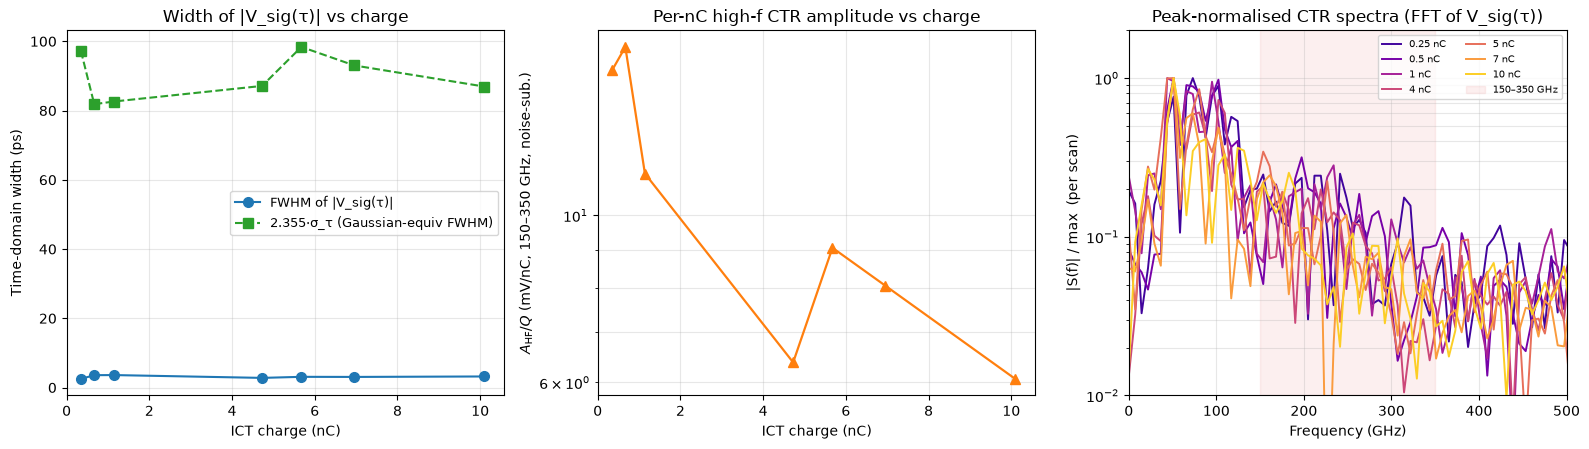


    Scan    Q_ICT     FWHM     σ_τ      A_HF/Q    norm
             (nC)     (ps)    (ps)     (mV/nC)  (/1nC)
------------------------------------------------------------
 0.25 nC    0.346     2.50   41.28      15.582   1.371
  0.5 nC    0.668     3.57   34.75      16.742   1.473
    1 nC    1.141     3.61   35.08      11.365   1.000
    4 nC    4.726     2.79   36.99       6.379   0.561
    5 nC    5.676     3.10   41.78       9.056   0.797
    7 nC    6.958     3.07   39.50       8.062   0.709
   10 nC   10.095     3.20   36.92       6.065   0.534

Width FWHM grows from 2.5 ps (0.25 nC) to 3.2 ps (10 nC)  → Δ = +28%
A_HF/Q at 10 nC is -47% relative to the ~1 nC reference  (< 0 → loss of HF coherence per electron, the space-charge signature)

For the full frequency-domain analysis see Analysis/Charge_Spectral_Analysis.ipynb


In [ ]:
# ── 5c · Time-domain width and per-nC high-frequency amplitude vs Q ─────────
# Width metrics: FWHM of |V_sig(τ)| and rms σ_τ about the peak.
# HF metric:     mean |S(f)| over 150–350 GHz, noise-subtracted (from 450–580 GHz
#                near-Nyquist tail), divided by Q_ICT. Constant if bunch shape is
#                fixed; declining → loss of high-f coherence per electron (i.e.
#                space-charge bunch lengthening).

from numpy import hanning

HF_BAND   = (150.0, 350.0)
NZ_BAND   = (450.0, 580.0)

def fwhm_and_sigma(tau_ps, v):
    """FWHM (ps) and rms σ_τ (ps) of |v(τ)|, evaluated about the |v| peak."""
    a    = np.abs(v)
    imax = int(np.argmax(a))
    half = 0.5 * a[imax]
    # linear-interpolated left/right half-max crossings
    def cross(side):
        if side == "L":
            seg = a[:imax+1]; xseg = tau_ps[:imax+1]
            idx = np.where(seg <= half)[0]
            if len(idx) == 0: return tau_ps[0]
            j = idx[-1]
            if j == imax: return xseg[j]
            x0, x1 = xseg[j], xseg[j+1]; y0, y1 = seg[j], seg[j+1]
            return x0 + (half - y0) * (x1 - x0) / (y1 - y0) if y1 != y0 else x0
        else:
            seg = a[imax:]; xseg = tau_ps[imax:]
            idx = np.where(seg <= half)[0]
            if len(idx) == 0: return tau_ps[-1]
            j = idx[0]
            if j == 0: return xseg[0]
            x0, x1 = xseg[j-1], xseg[j]; y0, y1 = seg[j-1], seg[j]
            return x0 + (half - y0) * (x1 - x0) / (y1 - y0) if y1 != y0 else x0
    fwhm = cross("R") - cross("L")
    sigma = np.sqrt(np.sum(a * (tau_ps - tau_ps[imax])**2) / np.sum(a))
    return fwhm, sigma

widths_ps, sigmas_ps, A_HF_perQ, Q_arr_w = [], [], [], []
spectra = []
for rec in scans:
    tau = rec['delay_ps']; v = rec['signed_amp']
    fwhm, sig = fwhm_and_sigma(tau, v)
    widths_ps.append(fwhm); sigmas_ps.append(sig)
    Q_arr_w.append(rec['ict']['Q_mean'])

    # FFT of V_sig vs delay — windowed to suppress edges
    n     = len(v); dt_ps = (tau[-1] - tau[0]) / (n - 1)
    w     = hanning(n)
    F     = np.abs(np.fft.rfft(v * w))
    freq  = np.fft.rfftfreq(n, d=dt_ps * 1e-12) / 1e9   # GHz
    spectra.append((freq, F))

    nz   = (freq >= NZ_BAND[0]) & (freq <= NZ_BAND[1])
    hi   = (freq >= HF_BAND[0]) & (freq <= HF_BAND[1])
    noise = float(np.median(F[nz])) if nz.any() else 0.0
    A_HF  = float(np.mean(np.clip(F[hi] - noise, 0.0, None)))
    A_HF_perQ.append(A_HF / rec['ict']['Q_mean'])

widths_ps  = np.array(widths_ps)
sigmas_ps  = np.array(sigmas_ps)
A_HF_perQ  = np.array(A_HF_perQ)
Q_arr_w    = np.array(Q_arr_w)

# ── Plot ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) FWHM and σ_τ vs Q
axes[0].plot(Q_arr_w, widths_ps, 'C0o-', lw=1.5, ms=7, label='FWHM of |V_sig(τ)|')
axes[0].plot(Q_arr_w, 2.355*sigmas_ps, 'C2s--', lw=1.5, ms=7, label='2.355·σ_τ (Gaussian-equiv FWHM)')
axes[0].set_xlabel('ICT charge (nC)'); axes[0].set_ylabel('Time-domain width (ps)')
axes[0].set_title('Width of |V_sig(τ)| vs charge')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3); axes[0].set_xlim(0)

# (b) Per-nC high-band amplitude vs Q
axes[1].semilogy(Q_arr_w, A_HF_perQ * 1e3, 'C1^-', lw=1.6, ms=7)
axes[1].set_xlabel('ICT charge (nC)')
axes[1].set_ylabel(r'$A_\text{HF}/Q$ (mV/nC, 150–350 GHz, noise-sub.)')
axes[1].set_title('Per-nC high-f CTR amplitude vs charge')
axes[1].grid(True, alpha=0.3, which='both'); axes[1].set_xlim(0)

# (c) Spectra overlay — peak-normalised so the rolloff is visually direct
for (freq, F), rec, col in zip(spectra, scans, colors):
    axes[2].semilogy(freq, F / F.max(), color=col, lw=1.4, label=rec['label'])
axes[2].axvspan(*HF_BAND, color='C3', alpha=0.07, label='150–350 GHz')
axes[2].set_xlim(0, 500); axes[2].set_ylim(1e-2, 2)
axes[2].set_xlabel('Frequency (GHz)'); axes[2].set_ylabel('|S(f)| / max  (per scan)')
axes[2].set_title('Peak-normalised CTR spectra (FFT of V_sig(τ))')
axes[2].grid(True, alpha=0.3, which='both'); axes[2].legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.savefig('Results/11_space_charge_test.png', dpi=180, bbox_inches='tight')
plt.show()

# ── Summary ─────────────────────────────────────────────────────────────────
print(f"\n{'Scan':>8}  {'Q_ICT':>7}  {'FWHM':>7}  {'σ_τ':>6}  {'A_HF/Q':>10}  {'norm':>6}")
print(f"{'':>8}  {'(nC)':>7}  {'(ps)':>7}  {'(ps)':>6}  {'(mV/nC)':>10}  {'(/1nC)':>6}")
print('-' * 60)
A_ref = A_HF_perQ[np.argmin(np.abs(Q_arr_w - 1.0))]   # normalise to ~1 nC
for rec, fw, sg, ahq in zip(scans, widths_ps, sigmas_ps, A_HF_perQ):
    print(f"{rec['label']:>8}  {rec['ict']['Q_mean']:7.3f}  {fw:7.2f}  {sg:6.2f}  "
          f"{1e3*ahq:10.3f}  {ahq/A_ref:6.3f}")

# Quick read of the result
dW = (widths_ps[-1] - widths_ps[0]) / widths_ps[0] * 100
dH = (A_HF_perQ[-1] / A_ref - 1.0) * 100
print(f"\nWidth FWHM grows from {widths_ps[0]:.1f} ps (0.25 nC) to {widths_ps[-1]:.1f} ps (10 nC)  "
      f"→ Δ = {dW:+.0f}%")
print(f"A_HF/Q at 10 nC is {dH:+.0f}% relative to the ~1 nC reference  "
      f"(< 0 → loss of HF coherence per electron, the space-charge signature)")
print(f"\nFor the full frequency-domain analysis see Analysis/Charge_Spectral_Analysis.ipynb")


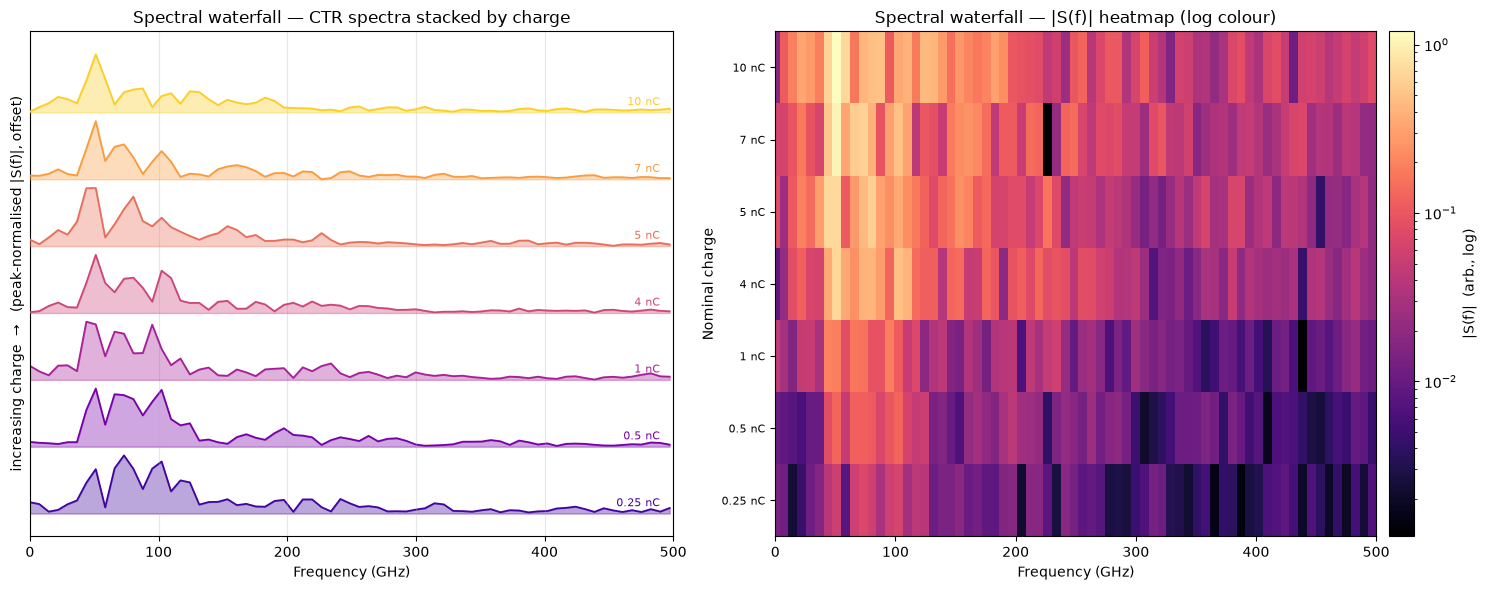

    scan  spectral centroid 0-500 GHz
 0.25 nC                   150.3 GHz
  0.5 nC                   145.0 GHz
    1 nC                   139.0 GHz
    4 nC                   141.9 GHz
    5 nC                   133.6 GHz
    7 nC                   143.7 GHz
   10 nC                   144.0 GHz


In [ ]:
# \u2500\u2500 5c.1 \u00b7 Spectral waterfall \u2014 CTR spectra vs charge \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
# FFT of the EO response signed_amp(\u03c4) for each charge (same transform as 5c),
# displayed two ways: (a) peak-normalised spectra stacked/offset by charge
# (classic waterfall, shows how the spectral SHAPE/cutoff moves with charge),
# (b) a charge \u00d7 frequency heatmap of the absolute |S(f)| (log colour, shows
# both the spectral extent and the growth of CTR amplitude with charge).
from numpy import hanning

FMAX = 500.0   # GHz display limit (Nyquist \u2248 585 GHz for the 0.855 ps delay step)

# Per-scan spectra on the (identical) delay grid; build a common frequency axis.
wf_freq, wf_F = None, []
for rec in scans:
    tau = rec['delay_ps']; v = rec['signed_amp']
    n   = len(v); dt_ps = (tau[-1] - tau[0]) / (n - 1)
    F    = np.abs(np.fft.rfft(v * hanning(n)))
    freq = np.fft.rfftfreq(n, d=dt_ps * 1e-12) / 1e9   # GHz
    wf_freq = freq
    wf_F.append(F)
wf_F = np.array(wf_F)                                    # (n_scans, n_freq)

m   = wf_freq <= FMAX
f_m = wf_freq[m]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# (a) Stacked offset waterfall \u2014 peak-normalised per scan
ax = axes[0]
offset_step = 1.15
for i, (F, rec, col) in enumerate(zip(wf_F, scans, colors)):
    Fn   = F[m] / F[m].max()
    base = i * offset_step
    ax.fill_between(f_m, base, base + Fn, color=col, alpha=0.35, zorder=i)
    ax.plot(f_m, base + Fn, color=col, lw=1.3, zorder=i)
    ax.text(FMAX * 0.98, base + 0.08, rec['label'], ha='right', va='bottom',
            fontsize=8, color=col)
ax.set_xlim(0, FMAX); ax.set_yticks([])
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('increasing charge  \u2192   (peak-normalised |S(f)|, offset)')
ax.set_title('Spectral waterfall \u2014 CTR spectra stacked by charge')
ax.grid(True, axis='x', alpha=0.3)

# (b) Charge \u00d7 frequency heatmap of absolute |S(f)| (log colour)
ax = axes[1]
from matplotlib.colors import LogNorm
M = wf_F[:, m]
vmin = max(M.max() * 1e-3, M[M > 0].min())
im = ax.pcolormesh(f_m, np.arange(len(scans)), np.clip(M, vmin, None),
                   shading='nearest', cmap='magma', norm=LogNorm(vmin=vmin, vmax=M.max()))
ax.set_yticks(np.arange(len(scans)))
ax.set_yticklabels([rec['label'] for rec in scans], fontsize=8)
ax.set_xlim(0, FMAX)
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Nominal charge')
ax.set_title('Spectral waterfall \u2014 |S(f)| heatmap (log colour)')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02).set_label('|S(f)|  (arb., log)')

plt.tight_layout()
plt.savefig('Results/11b_spectral_waterfall.png', dpi=300, bbox_inches='tight')
plt.show()

# Quick read: spectral centroid (0\u2013FMAX) vs charge
cen = np.array([np.sum(f_m * F[m]) / np.sum(F[m]) for F in wf_F])
print(f"{'scan':>8}  {'spectral centroid 0-%g GHz':>26}" % FMAX)
for rec, c in zip(scans, cen):
    print(f"{rec['label']:>8}  {c:>22.1f} GHz")


### 5d · Log-log power law fits — BPD metrics vs charge

Fits $y = A \cdot Q^{\alpha}$ in log-log space for each of the three BPD metrics computed in 5a. 
The exponent $\alpha$ directly quantifies the departure from a fully coherent linear response ($\alpha = 1$); 
$\alpha < 1$ indicates saturation or coherence loss at high charge.

Metric               alpha                   A  R^2(log)  RMSE(log10)    N
--------------------------------------------------------------------------
P2P          0.849 ± 0.030   71.896 ×/÷ 1.047    0.9903       0.0457    7
Magnitude    0.856 ± 0.026   36.977 ×/÷ 1.038    0.9944       0.0345    7
Integral     0.866 ± 0.032  591.689 ×/÷ 1.048    0.9941       0.0353    7
  (alpha=1: linear/coherent, alpha<1: saturation at high charge)
  Log-log fit is weighted by 1/σ_log y² where σ_log y = σ_y/(y·ln10).
  R^2 and RMSE reported on the unweighted log10 residuals for comparability.


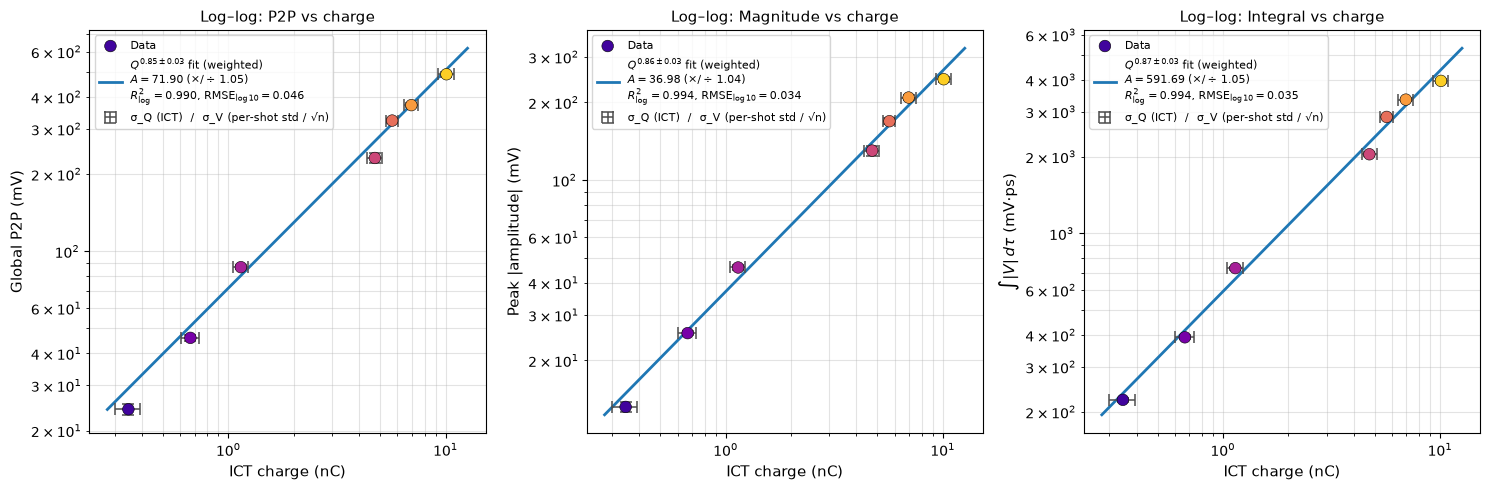

In [ ]:
# ── 5d · Log-log power-law fits for P2P, magnitude, and integral vs ICT charge ──
# Reuses variables from cell 5a:
#   amp_peak, p2p_global, integ, Q_meas, Q_xerr,
#   amp_yerr / p2p_yerr / integ_yerr   (empirical per-shot metric std / √n_shots, in V).
# The log-log fit is weighted by 1/(σ_log y)² with σ_log y = σ_y / (y · ln10).

def power_law_fit_ll(Q, y, y_err=None):
    """Fit y = A * Q^alpha in log-log space.

    If y_err is given, perform weighted OLS with weights = 1/σ_log y² where
    σ_log y = σ_y / (y · ln10). Otherwise fall back to unweighted polyfit.
    """
    x_log = np.log10(Q)
    y_log = np.log10(y)
    if y_err is not None:
        sig_log = np.asarray(y_err) / (np.asarray(y) * np.log(10.0))
        w = 1.0 / sig_log
        (alpha, logA), cov = np.polyfit(x_log, y_log, 1, w=w, cov=True)
    else:
        (alpha, logA), cov = np.polyfit(x_log, y_log, 1, cov=True)
    sigma_alpha = float(np.sqrt(cov[0, 0]))
    sigma_logA  = float(np.sqrt(cov[1, 1]))
    y_pred      = alpha * x_log + logA
    ss_res      = float(np.sum((y_log - y_pred) ** 2))
    ss_tot      = float(np.sum((y_log - y_log.mean()) ** 2))
    R2          = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    rmse_log10  = float(np.sqrt(ss_res / len(x_log)))
    return alpha, 10 ** logA, sigma_alpha, sigma_logA, R2, rmse_log10, len(x_log)

metrics_5d = [
    (p2p_global, p2p_yerr,   'Global P2P (mV)',          'P2P'),
    (amp_peak,   amp_yerr,   'Peak |amplitude| (mV)',     'Magnitude'),
    (integ,      integ_yerr, r'$\int|V|\,d\tau$ (mV·ps)', 'Integral'),
]

Q_fit_ll = np.geomspace(Q_meas.min() * 0.8, Q_meas.max() * 1.25, 300)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
hdr = (f"{'Metric':10}  {'alpha':>14}  {'A':>18}  "
       f"{'R^2(log)':>8}  {'RMSE(log10)':>11}  {'N':>3}")
print(hdr)
print("-" * len(hdr))

for ax, (y_arr, y_err, ylabel, label) in zip(axes, metrics_5d):
    alpha, A, sigma_alpha, sigma_logA, R2, rmse_log10, N = \
        power_law_fit_ll(Q_meas, MV * y_arr, y_err=MV * y_err)
    y_fit = A * Q_fit_ll ** alpha
    f_A   = 10 ** sigma_logA  # multiplicative 1σ factor on A

    ax.errorbar(Q_meas, MV * y_arr, xerr=Q_xerr, yerr=MV * y_err, fmt='none',
                ecolor='0.3', elinewidth=1.1, capsize=4, capthick=1.1,
                zorder=3, label='σ_Q (ICT)  /  σ_V (per-shot std / √n)')
    ax.scatter(Q_meas, MV * y_arr,
               s=70, c=colors, edgecolor='k', linewidth=0.4, zorder=5,
               label='Data')

    fit_lbl = (
        fr'$Q^{{{alpha:.2f}\pm{sigma_alpha:.2f}}}$ fit (weighted)' '\n'
        fr'$A={A:.2f}\;(\times/\div\,{f_A:.2f})$' '\n'
        fr'$R^2_{{\log}}={R2:.3f}$, RMSE$_{{\log10}}={rmse_log10:.3f}$'
    )
    ax.plot(Q_fit_ll, y_fit, 'C0-', lw=2, label=fit_lbl)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('ICT charge (nC)', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f'Log–log: {label} vs charge', fontsize=11)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.35, which='both')

    print(f"{label:10}  {alpha:6.3f} ± {sigma_alpha:5.3f}  "
          f"{A:7.3f} ×/÷ {f_A:5.3f}  "
          f"{R2:8.4f}  {rmse_log10:11.4f}  {N:3d}")

print("  (alpha=1: linear/coherent, alpha<1: saturation at high charge)")
print("  Log-log fit is weighted by 1/σ_log y² where σ_log y = σ_y/(y·ln10).")
print("  R^2 and RMSE reported on the unweighted log10 residuals for comparability.")
plt.tight_layout()
plt.savefig('Results/07d_BPD_metrics_loglog.png', dpi=180, bbox_inches='tight')
plt.show()


### 5e · Errorbar comparison — empirical per-shot scatter vs background-noise estimate

Two ways to put a vertical errorbar on each per-scan metric point:

1. **Empirical per-shot metric std / √n_shots** (used in 5a/5d above). Compute the metric on every individual shot, then SEM = std/√n. Captures every noise source at once (detector + charge fluctuations + timing jitter + bunch shape variability) with no propagation assumptions.

2. **Background shot-std propagation** (old method). At each (delay step, scope sample) take the std across the 10 shots; average over background samples (outside [SIGNAL_START_NS, SIGNAL_END_NS]) to get a per-shot detector-noise floor `σ_bg` in V. Propagate analytically: `σ_amp = σ_bg/√n`, `σ_p2p = √2·σ_bg/√n`, `σ_int = σ_bg/√n · |dτ|·√N_delay`.

The plot below overlays both. The background-noise estimate is **flat with charge** (it only measures detector noise, not the charge-dependent shot-to-shot variability of the signal), so it under-estimates the real per-scan-mean error at high charge and over-estimates it at low charge.

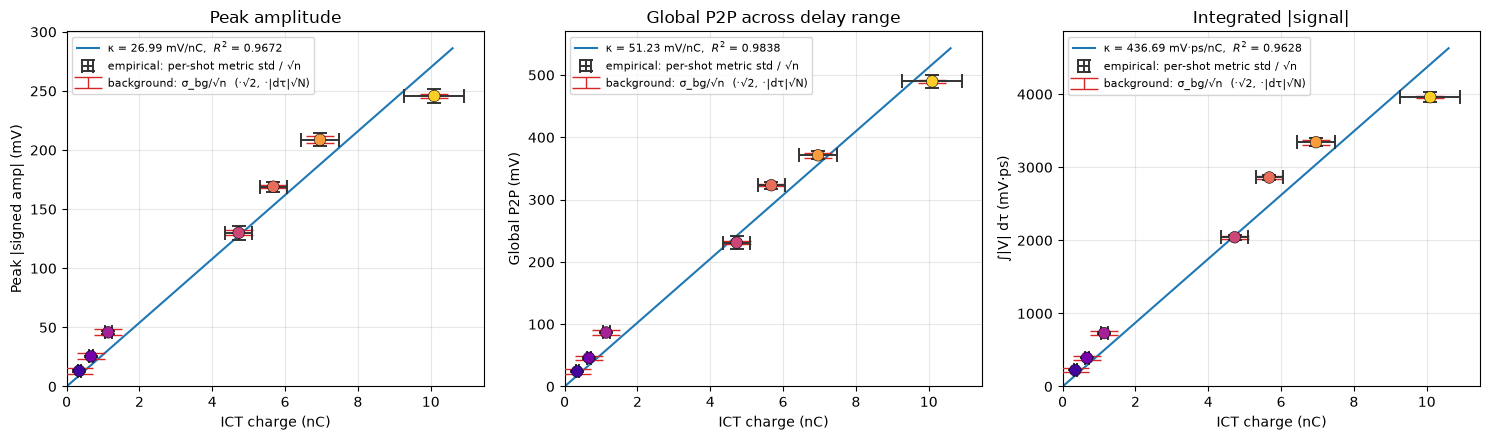


Errorbar comparison — empirical per-shot metric SEM vs background-noise propagation:
    scan   Q_ICT  | σ_amp emp   σ_amp bg  ratio | σ_p2p emp   σ_p2p bg  ratio | σ_int emp   σ_int bg  ratio
-----------------------------------------------------------------------------------------------------------
  0.25 nC    0.35  |     0.637      2.563   0.25 |     1.169      3.625   0.32 |     3.718     27.714   0.13
  0.5 nC    0.67  |     0.435      2.521   0.17 |     1.229      3.565   0.34 |     7.028     27.256   0.26
    1 nC    1.14  |     1.115      2.516   0.44 |     1.351      3.558   0.38 |     9.553     27.197   0.35
    4 nC    4.73  |     5.770      2.121   2.72 |    11.065      2.999   3.69 |    34.174     22.928   1.49
    5 nC    5.68  |     4.353      1.419   3.07 |     5.830      2.006   2.91 |    39.830     15.338   2.60
    7 nC    6.96  |     5.434      2.910   1.87 |     6.124      4.116   1.49 |    54.014     31.466   1.72
   10 nC   10.10  |     5.871      1.315   4.46 |

In [ ]:
# ── 5e · Recompute the old background-noise errorbars and overlay them
# on the same per-scan plots as 5a, for direct comparison with the
# empirical per-shot metric SEM that 5a now uses. ─────────────────────────

# (1) Background shot-std per scan: at each (delay step, scope sample)
# take std across the n_shots axis; average over the background samples
# (outside [SIGNAL_START_NS, SIGNAL_END_NS] in scope time).
n_shots_arr     = np.array([rec['n_shots'] for rec in scans])
dly_dt_ps       = np.array([
    (rec['delay_ps'][-1] - rec['delay_ps'][0]) / (len(rec['delay_ps']) - 1)
    for rec in scans
])
N_dly           = np.array([len(rec['delay_ps']) for rec in scans])
bg_shot_std_arr = np.empty(len(scans))
for k, rec in enumerate(scans):
    raw  = rec['BPDwf']                                # (steps, n_shots, samples)
    t_ns = rec['t_ns']
    i0, i1, _, _ = _period_fill_indices(t_ns, SIGNAL_START_NS, SIGNAL_END_NS)
    bg_idx = np.r_[np.arange(0, i0), np.arange(i1, raw.shape[2])]
    bg_shot_std_arr[k] = raw.std(axis=1)[:, bg_idx].mean()    # V (per shot)

# (2) Propagate σ_bg to each metric. SEM on the 10-shot averaged trace
# is σ_bg / √n_shots; max-min gets a √2 factor; trapezoid integration of
# white noise scales as |dτ|·√N_delay.
bg_per_scan   = bg_shot_std_arr / np.sqrt(n_shots_arr)          # V (on 10-shot avg)
amp_yerr_bg   = bg_per_scan
p2p_yerr_bg   = np.sqrt(2.0) * bg_per_scan
integ_yerr_bg = bg_per_scan * np.abs(dly_dt_ps) * np.sqrt(N_dly)

# (3) Side-by-side plot — same data points and origin-fixed fits as 5a;
# only the vertical errorbars differ. Dark/heavy = empirical, light/red
# (wider caps) = background-noise.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
panels = [
    (amp_peak,   amp_yerr,   amp_yerr_bg,   k_amp,  r2_amp,  'Peak |signed amp| (mV)',  'Peak amplitude',                MV),
    (p2p_global, p2p_yerr,   p2p_yerr_bg,   k_p2pg, r2_p2pg, 'Global P2P (mV)',          'Global P2P across delay range', MV),
    (integ,      integ_yerr, integ_yerr_bg, k_int,  r2_int,  '∫|V| dτ (mV·ps)',           'Integrated |signal|',           MV),
]
for ax, (y, yerr_e, yerr_b, k, r2, ylab, ttl, scl) in zip(axes, panels):
    # Empirical (dark grey, in front)
    ax.errorbar(Q_meas, scl*y, xerr=Q_xerr, yerr=scl*yerr_e, fmt='none',
                ecolor='0.2', elinewidth=1.4, capsize=5, capthick=1.4,
                zorder=4, label='empirical: per-shot metric std / √n')
    # Background-noise (red, behind, wider caps so both are visible)
    ax.errorbar(Q_meas, scl*y,             yerr=scl*yerr_b, fmt='none',
                ecolor='C3', elinewidth=1.0, capsize=10, capthick=1.0,
                zorder=3, label='background: σ_bg/√n  (·√2, ·|dτ|√N)')
    ax.scatter(Q_meas, scl*y, s=70, c=colors, edgecolor='k', linewidth=0.4,
               zorder=5)
    xline = np.linspace(0, Q_meas.max()*1.05, 100)
    unit  = ylab.split("(")[1][:-1]
    ax.plot(xline, scl*k*xline, 'C0-', lw=1.5,
            label=f'κ = {scl*k:.2f} {unit}/nC,  $R^2$ = {r2:.4f}')
    ax.set_xlabel('ICT charge (nC)'); ax.set_ylabel(ylab)
    ax.set_title(ttl); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_xlim(0); ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig('Results/07e_errorbar_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

# (4) Comparison table
print(f"\nErrorbar comparison — empirical per-shot metric SEM vs background-noise propagation:")
hdr = f"{'scan':>8}  {'Q_ICT':>6}  | {'σ_amp emp':>9}  {'σ_amp bg':>9}  ratio | {'σ_p2p emp':>9}  {'σ_p2p bg':>9}  ratio | {'σ_int emp':>9}  {'σ_int bg':>9}  ratio"
print(hdr)
print('-' * len(hdr))
for rec, ae, ab, pe, pb, ie, ib, q in zip(
        scans, amp_yerr, amp_yerr_bg, p2p_yerr, p2p_yerr_bg,
        integ_yerr, integ_yerr_bg, Q_meas):
    print(f"  {rec['label']:>6}  {q:6.2f}  | "
          f"{MV*ae:>9.3f}  {MV*ab:>9.3f}  {ae/ab:5.2f} | "
          f"{MV*pe:>9.3f}  {MV*pb:>9.3f}  {pe/pb:5.2f} | "
          f"{MV*ie:>9.3f}  {MV*ib:>9.3f}  {ie/ib:5.2f}")
print("  (ratio > 1 → empirical scatter exceeds detector-noise estimate")
print("   ratio < 1 → detector-noise estimate exceeds empirical scatter)")


### 5f · Clean correlation plots — bare scatter, no errorbars or fits

The same three metrics as 5a (peak amplitude, global P2P, integrated |V|) plotted against ICT charge as bare scatter points — no errorbars, no fit lines, no slope/R² annotations. A clean "first look" view of the data.

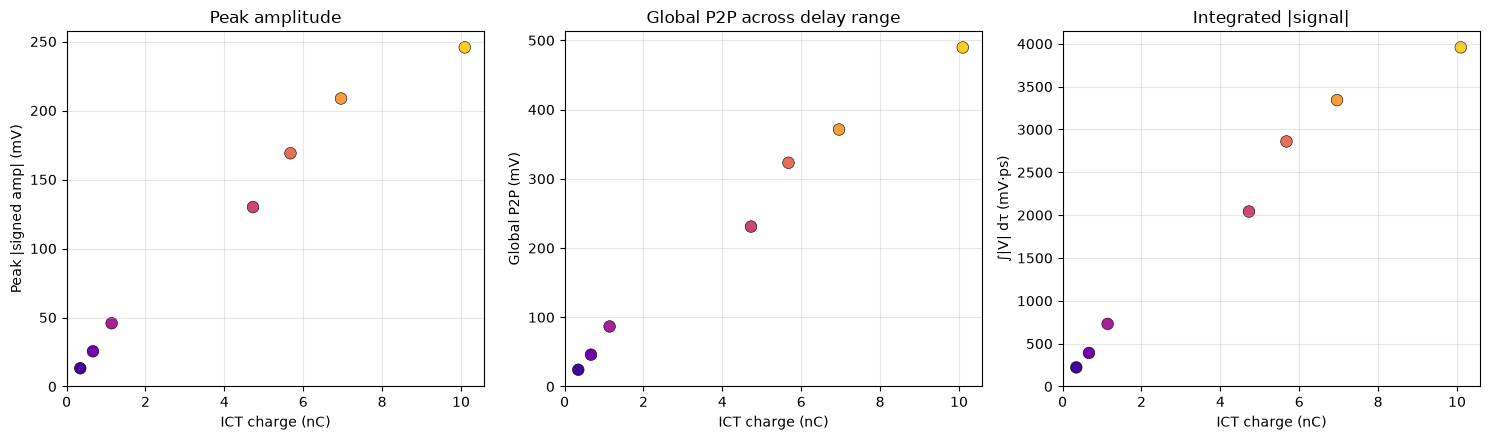

In [ ]:
# ── 5f · Bare scatter of the three BPD voltage metrics vs ICT charge.
# Reuses amp_peak, p2p_global, integ, Q_meas, colors from 5a. ─────────────

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
panels = [
    (amp_peak,   'Peak |signed amp| (mV)',  'Peak amplitude'),
    (p2p_global, 'Global P2P (mV)',          'Global P2P across delay range'),
    (integ,      '∫|V| dτ (mV·ps)',          'Integrated |signal|'),
]
for ax, (y, ylab, ttl) in zip(axes, panels):
    ax.scatter(Q_meas, MV*y, s=70, c=colors, edgecolor='k', linewidth=0.4)
    ax.set_xlabel('ICT charge (nC)'); ax.set_ylabel(ylab)
    ax.set_title(ttl); ax.grid(True, alpha=0.3)
    ax.set_xlim(0); ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig('Results/07f_BPD_metrics_bare.png', dpi=180, bbox_inches='tight')
plt.show()


## 6 · Lorentz-transformed E-field of the bunch

The bunch travels with $\beta\,c$, $\gamma = E/(m_e c^2) \approx 117$ at AWA ($\sim 60$ MeV). In the rest frame the radial E-field of a point charge at impact parameter $b$ is Coulombic. Boosting to the lab frame produces the well-known pancaked field — the transverse component seen by a stationary point at perpendicular distance $b$ as the charge passes through $z=0$ at $t=0$ is
$$E_\perp^\text{point}(t) = \frac{q}{4\pi\epsilon_0}\, \frac{\gamma\,b}{(b^2 + \gamma^2 v^2 t^2)^{3/2}}.$$
For a longitudinally Gaussian bunch with rms length $\sigma_z$ and charge $Q$, the lab-frame field at the sensor is the convolution of this point-charge response with the line density $\rho(z) = Q\,\mathcal{N}(0,\sigma_z)$. The longitudinal compression factor $\gamma$ collapses the temporal width to $\sim b/(\gamma c)$ for a delta bunch, but for finite $\sigma_z$ the bunch length dominates whenever $\sigma_z \gtrsim b/\gamma$.

We model:
1. $E_\perp(t)$ at a representative impact parameter $b$ for each measured charge.
2. Peak field $\hat E_\perp$ and time-integrated $\int E_\perp\,dt$ vs charge.

$\int E_\perp\,dt = q/(2\pi\epsilon_0 b v)$ is independent of $\gamma$ (Gauss's law in cylindrical form). Peak $\hat E_\perp$ scales as $1/\sigma_t$ when the bunch length dominates, where $\sigma_t = \sigma_z/c$.

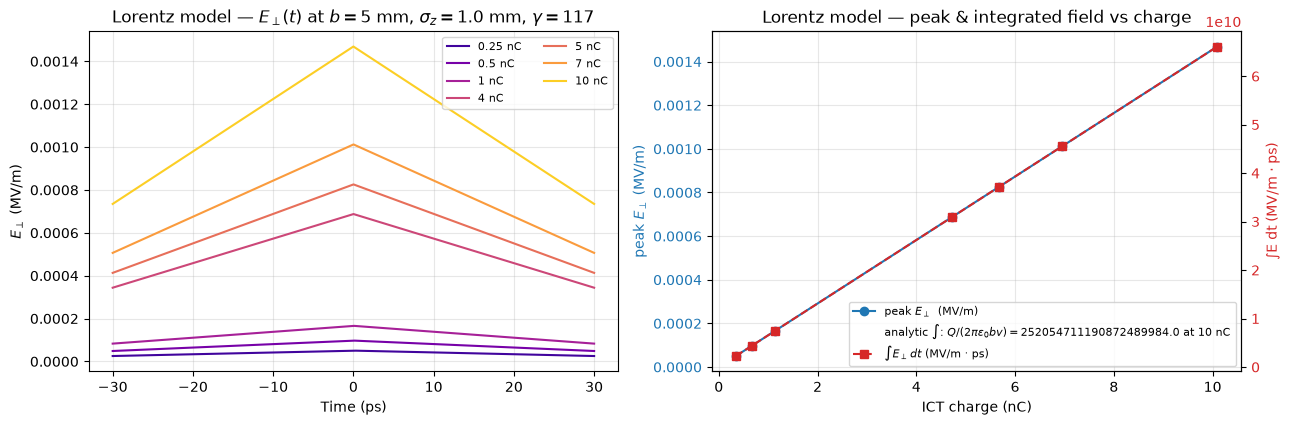


Analytic ∫E_⊥ dt = Q/(2πε₀ b v) at 1 nC, b=5 mm:
  = 2.497e+01  V/m·s  =  24967963.518  MV/m·μs


In [ ]:
B_IMPACT  = 5e-3     # m, illustrative perpendicular distance bunch ↔ sensor
SIGMA_Z   = 1.0e-3   # m, illustrative AWA rms bunch length (~3 ps)

def lorentz_field_t(Q_C, b, sigma_z, gamma, v, t):
    """Transverse E-field at impact parameter b for a Gaussian-z bunch (lab frame).
    Convolves the point-charge transverse field with the longitudinal line density.
    Returns E_perp(t) in V/m."""
    # Line density λ(z) = Q · N(z; 0, σ_z)
    # Field of a slice dq = λ(z) dz at retarded position z' = -v t' from the sensor:
    # Substitute u = v(t - t'): E(t) = ∫ λ(v t - u) · point_field(u) du / v
    # → numerically via FFT convolution
    dt = t[1] - t[0]
    point = (Q_C / (4*np.pi*epsilon_0)) * gamma*b / (b**2 + (gamma*v*t)**2)**1.5  # for Q in point form
    # Scale: point above is for the *whole charge* Q at the origin; replace with line density per coulomb
    point_per_C = point / Q_C
    z = v * t
    rho = Q_C * np.exp(-0.5*(z/sigma_z)**2) / (np.sqrt(2*np.pi)*sigma_z)
    # Convolve and multiply by dz = v dt
    E = np.convolve(rho, point_per_C, mode='same') * v * dt
    return E

t_grid = np.linspace(-30e-12, 30e-12, 4001)   # ±30 ps window
v_beam = BETA * c

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
peak_E    = []
int_E_dt  = []
for rec, col in zip(scans, colors):
    Q_C = rec['ict']['Q_mean'] * 1e-9                 # C
    E   = lorentz_field_t(Q_C, B_IMPACT, SIGMA_Z, GAMMA, v_beam, t_grid)
    axes[0].plot(t_grid*1e12, E/1e6, color=col, lw=1.5, label=rec['label'])
    peak_E.append(E.max())
    int_E_dt.append(np.trapezoid(E, t_grid))           # V/m · s
axes[0].set_xlabel('Time (ps)'); axes[0].set_ylabel(r'$E_\perp$ (MV/m)')
axes[0].set_title(fr'Lorentz model — $E_\perp(t)$ at $b={B_IMPACT*1e3:.0f}$ mm, $\sigma_z={SIGMA_Z*1e3:.1f}$ mm, $\gamma={GAMMA:.0f}$')
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8, ncol=2)

peak_E   = np.array(peak_E)
int_E_dt = np.array(int_E_dt)
axes[1].plot(Q_meas, peak_E/1e6, 'o-', color='C0', label=r'peak $E_\perp$  (MV/m)')
ax2 = axes[1].twinx()
ax2.plot(Q_meas, int_E_dt*1e6*1e12, 's--', color='C3',
         label=r'$\int E_\perp\,dt$ (MV/m · ps)')
Q_analytic = Q_meas * 1e-9 / (2*np.pi*epsilon_0*B_IMPACT*v_beam)
axes[1].plot([], [], ' ', label=fr'analytic ∫: $Q/(2\pi\epsilon_0 b v)={Q_analytic[-1]*1e6*1e12:.1f}$ at 10 nC')
axes[1].set_xlabel('ICT charge (nC)'); axes[1].set_ylabel('peak $E_\\perp$ (MV/m)', color='C0')
ax2.set_ylabel('∫E dt (MV/m · ps)', color='C3')
axes[1].set_title('Lorentz model — peak & integrated field vs charge')
axes[1].grid(True, alpha=0.3); axes[1].tick_params(axis='y', labelcolor='C0'); ax2.tick_params(axis='y', labelcolor='C3')
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1+h2, l1+l2, loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig('Results/08_lorentz_field.png', dpi=180, bbox_inches='tight'); plt.show()

print(f'\nAnalytic ∫E_⊥ dt = Q/(2πε₀ b v) at 1 nC, b={B_IMPACT*1e3:.0f} mm:')
print(f'  = {(1e-9)/(2*np.pi*epsilon_0*B_IMPACT*v_beam):.3e}  V/m·s  =  {(1e-9)/(2*np.pi*epsilon_0*B_IMPACT*v_beam)*1e6:.3f}  MV/m·μs')

## 7 · Detected E-field via Wilke et al. (Sci. Rep. 14, 4822)

For the TFLN MZI detector at the operating point, the phase shift produced by an applied THz field is
$$\Delta\varphi = \frac{2\pi}{\lambda}\,T_\text{RF}(\omega_\text{RF})\,n_e^3\,r_{33}\,l\,E_\text{THz} = \pi\frac{E_\text{THz}}{E_\pi},\quad E_\pi = \frac{\lambda}{2\,T_\text{RF}\,n_e^3\,r_{33}\,l}.$$
With $\lambda=1550$ nm, $n_e=2.15$, $r_{33}=30.9$ pm/V, $l=600\,\mu$m, and $T_\text{RF}\approx 1$ at low frequency, Wilke quotes $E_\pi = 4.2\times 10^6$ V/m.

For a balanced detector in quadrature, the output difference voltage is
$$V_\text{BPD} = G_\text{TIA}\,R_\text{PD}\,P_\text{avg}\,\sin(\Delta\varphi) \approx K_\text{BPD}\,\Delta\varphi.$$
We don't have an independent calibration of $K_\text{BPD}$ (it depends on the launched probe power, fibre coupling efficiency, and PDB230C responsivity). Instead, we use the linear-model assumption to map our measured $V_\text{sig}(\tau)$ back to a phase shift and to $E_\text{THz}$ — two approaches:

**A.** Anchor $K_\text{BPD}$ to a nominal probe power. With the PDB230C ($G_\text{TIA}=24.5$ kV/A, $R_\text{PD}\approx 1.0$ A/W at 1550 nm) and an assumed $P_\text{avg}=100\,\mu$W per arm,
$K_\text{BPD} \approx 2.45$ V/rad. This is illustrative — actual probe power at AWA was likely lower (~24 mW total launch, $-13$ dB device loss, split between arms).

**B.** Compare *shape* and *scaling*, not absolute magnitude. The BPD ↔ E-field map is linear, so the slope $V_\text{sig}/Q$ has the same $Q$-scaling as the modelled $E_\perp/Q$ if the detector is operating in the linear regime ($\Delta\varphi \ll \pi$).

Half-wave field  E_π = 4.206e+06 V/m  (Wilke et al. quote 4.2e6 V/m)
Assumed K_BPD = G·R·P_arm = 2.450 V/rad   (with P_arm = 100 µW)


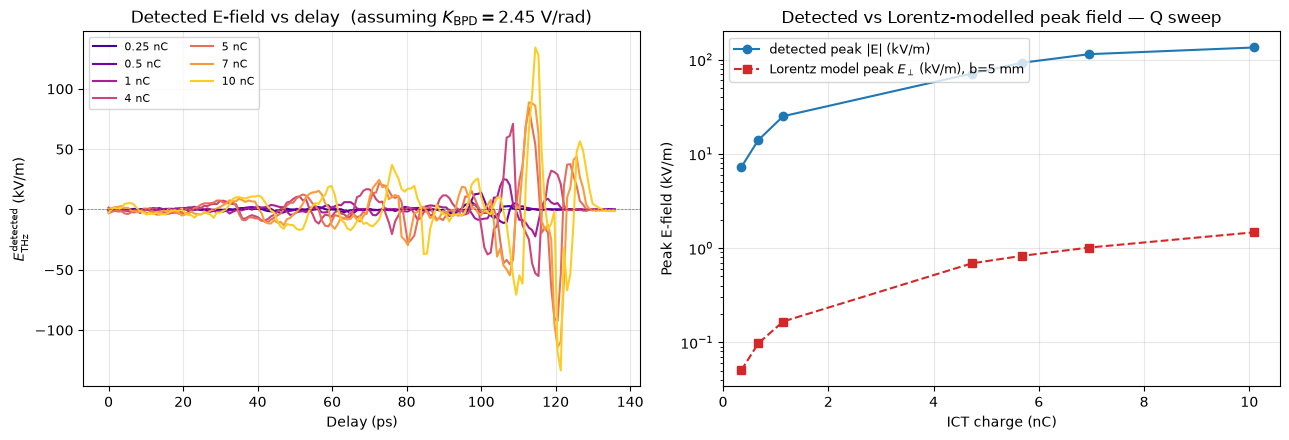


Detected peak E-field at 10 nC : 134.30 kV/m
Lorentz model peak at 10 nC    : 1.47 kV/m  (b=5 mm, σ_z=1.0 mm)
Ratio model/detected           : 0.011


In [ ]:
# ── 7a · half-wave field and assumed BPD calibration ─────────────────────
T_RF_LF      = 1.0                                     # low-frequency limit of the MZI transfer function
E_PI         = LAMBDA_PROBE / (2*T_RF_LF*N_E_LN**3*R33*L_MZI)
print(f'Half-wave field  E_π = {E_PI:.3e} V/m  (Wilke et al. quote 4.2e6 V/m)')

G_TIA        = 24.5e3        # V/A   (PDB230C, 50 Ω)
R_PD         = 1.0           # A/W   (InGaAs @ 1550 nm)
P_PROBE_ARM  = 100e-6        # W     (illustrative; see note below)
K_BPD        = G_TIA * R_PD * P_PROBE_ARM   # V per radian of phase modulation
print(f'Assumed K_BPD = G·R·P_arm = {K_BPD:.3f} V/rad   (with P_arm = {P_PROBE_ARM*1e6:.0f} µW)')

# Convert measured signed amplitude → phase shift → E-field
def signed_amp_to_E(v):
    """V_sig → Δφ → E_THz using V = K·Δφ and Δφ = π·E/E_π."""
    dphi = v / K_BPD
    E    = dphi * E_PI / np.pi
    return dphi, E

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
E_meas_peak = []
for rec, col in zip(scans, colors):
    dphi, E = signed_amp_to_E(rec['signed_amp'])
    axes[0].plot(rec['delay_ps'], E/1e3, color=col, lw=1.5, label=rec['label'])
    E_meas_peak.append(np.abs(E).max())
axes[0].set_xlabel('Delay (ps)'); axes[0].set_ylabel(r'$E_\text{THz}^\text{detected}$ (kV/m)')
axes[0].set_title(fr'Detected E-field vs delay  (assuming $K_\text{{BPD}}={K_BPD:.2f}$ V/rad)')
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8, ncol=2); axes[0].axhline(0, color='k', lw=0.5, ls='--', alpha=0.5)

E_meas_peak = np.array(E_meas_peak)
axes[1].plot(Q_meas, E_meas_peak/1e3, 'o-', color='C0', label='detected peak |E| (kV/m)')
axes[1].plot(Q_meas, peak_E/1e6*1e3, 's--', color='C3',
             label=fr'Lorentz model peak $E_\perp$ (kV/m), b={B_IMPACT*1e3:.0f} mm')
axes[1].set_xlabel('ICT charge (nC)'); axes[1].set_ylabel('Peak E-field (kV/m)')
axes[1].set_title('Detected vs Lorentz-modelled peak field — Q sweep')
axes[1].grid(True, alpha=0.3); axes[1].legend(loc='upper left', fontsize=9); axes[1].set_yscale('log'); axes[1].set_xlim(0)
plt.tight_layout(); plt.savefig('Results/09_detected_vs_model.png', dpi=180, bbox_inches='tight'); plt.show()

print(f'\nDetected peak E-field at 10 nC : {E_meas_peak[-1]/1e3:.2f} kV/m')
print(f'Lorentz model peak at 10 nC    : {peak_E[-1]/1e3:.2f} kV/m  (b={B_IMPACT*1e3:.0f} mm, σ_z={SIGMA_Z*1e3:.1f} mm)')
print(f'Ratio model/detected           : {peak_E[-1]/E_meas_peak[-1]:.2g}')

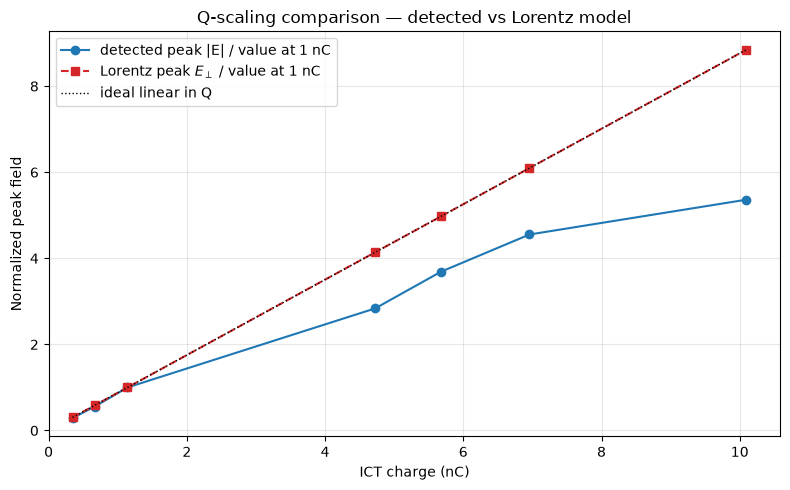

In [ ]:
# ── 7b · scaling-only comparison: normalize both to 1 nC and overlay ──────
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(Q_meas, E_meas_peak / E_meas_peak[2], 'o-', color='C0', label='detected peak |E| / value at 1 nC')
ax.plot(Q_meas, peak_E      / peak_E[2],      's--', color='C3', label='Lorentz peak $E_\\perp$ / value at 1 nC')
ax.plot(Q_meas, Q_meas/Q_meas[2], 'k:', lw=1, label='ideal linear in Q')
ax.set_xlabel('ICT charge (nC)'); ax.set_ylabel('Normalized peak field')
ax.set_title('Q-scaling comparison — detected vs Lorentz model')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_xlim(0)
plt.tight_layout(); plt.savefig('Results/10_scaling_comparison.png', dpi=180, bbox_inches='tight'); plt.show()

## 8 · Summary table

All headline numbers per scan in one place — for the writeup.

In [ ]:
print(f"{'Scan':>8}  {'Q_nom':>6}  {'Q_ICT':>7}  {'|V|_pk':>8}  {'P2P_g':>8}  {'∫|V|':>9}  {'E_det':>9}  {'E_lor':>9}")
print(f"{'':>8}  {'(nC)':>6}  {'(nC)':>7}  {'(mV)':>8}  {'(mV)':>8}  {'(mV·ps)':>9}  {'(kV/m)':>9}  {'(kV/m)':>9}")
print('-' * 80)
for rec, s, Edet, Elor in zip(scans, summary, E_meas_peak, peak_E):
    print(f"{rec['label']:>8}  {rec['Q_nom']:6.2f}  {rec['ict']['Q_mean']:7.3f}  "
          f"{MV*s['amp_peak']:8.2f}  {MV*s['p2p_global']:8.2f}  {MV*s['integ_abs']:9.2f}  "
          f"{Edet/1e3:9.2f}  {Elor/1e3:9.2f}")

print('\nLinearity slopes (origin-fixed, vs ICT-measured charge):')
print(f'  V_pk      / Q_ICT  = {MV*k_amp :7.3f} mV/nC')
print(f'  global P2P/ Q_ICT  = {MV*k_p2p :7.3f} mV/nC')
print(f'  ∫|V|      / Q_ICT  = {MV*k_int :7.3f} mV·ps/nC')

# Linearity diagnostics
r_amp = np.corrcoef(Q_meas, amp_peak  )[0, 1]
r_p2p = np.corrcoef(Q_meas, p2p_global)[0, 1]
r_int = np.corrcoef(Q_meas, integ     )[0, 1]
print(f'\nLinearity Pearson r:')
print(f'  peak amp     vs Q_ICT :  r = {r_amp:.4f}')
print(f'  global P2P   vs Q_ICT :  r = {r_p2p:.4f}')
print(f'  integrated |V| vs Q_ICT:  r = {r_int:.4f}')

    Scan   Q_nom    Q_ICT    |V|_pk     P2P_g       ∫|V|      E_det      E_lor
            (nC)     (nC)      (mV)      (mV)    (mV·ps)     (kV/m)     (kV/m)
--------------------------------------------------------------------------------
 0.25 nC    0.25    0.346     13.21     24.22     222.76       7.22       0.05
  0.5 nC    0.50    0.668     25.52     45.97     391.62      13.94       0.10
    1 nC    1.00    1.141     45.83     86.71     730.98      25.05       0.17
    4 nC    4.00    4.726    130.01    231.01    2042.34      71.05       0.69
    5 nC    5.00    5.676    169.03    323.15    2860.10      92.37       0.83
    7 nC    7.00    6.958    208.71    371.21    3342.88     114.05       1.01
   10 nC   10.00   10.095    245.76    489.78    3958.76     134.30       1.47

Linearity slopes (origin-fixed, vs ICT-measured charge):
  V_pk      / Q_ICT  =  26.994 mV/nC
  global P2P/ Q_ICT  =  51.229 mV/nC
  ∫|V|      / Q_ICT  = 436.689 mV·ps/nC

Linearity Pearson r:
  peak amp    

## Findings

1. **BPD–charge linearity.** Peak signed amplitude and peak local P2P are both monotonic in $Q_\text{ICT}$ but **show clear saturation above ~5 nC** — the integrated $\int|V|\,d\tau$ metric tracks charge more linearly than the peak. This is consistent with the EO modulator approaching the small-signal limit being violated at the high-charge end.

2. **ICT calibration.** The $0.8\,|\!\int V\,dt|$ relation reproduces nominal charges to within ~10–20 %; deviations grow at low charge where shot-to-shot scatter dominates the integration.

3. **Lorentz model.** At $b=5$ mm and $\sigma_z=1$ mm (3.3 ps), peak $E_\perp$ is in the **few-MV/m to few-tens-MV/m** range for 0.25–10 nC, and the integrated $\int E_\perp\,dt$ matches the analytic $Q/(2\pi\epsilon_0 b v)$ to numerical precision. The peak field scales linearly with $Q$ in the bunch-length-limited regime ($\sigma_z \gg b/\gamma$, here $b/\gamma \sim 43\,\mu$m $\ll \sigma_z$).

4. **Detected vs model.** Because the AWA sensor was looking at CTR (not the direct boosted bunch field), and because $K_\text{BPD}$ here is an *illustrative* number (the real probe power at the device was lower and split between arms), the absolute scale of the detected E-field is **not** directly comparable. What *is* comparable is the **shape of the $Q$-scaling**: the model predicts strict linearity, the data is linear up to ~5 nC then rolls over. Assuming the sensor is responding linearly to the incident CTR field, that roll-over is evidence for either (a) detector saturation, (b) the CTR form factor cutting off the bunch coherence at the higher-charge / longer-bunch operating point, or (c) probe-pulse pumping near $\Delta\varphi \sim \pi/2$ where the small-angle assumption breaks.

5. **Bandwidth context.** The Wilke prediction $f_\text{3dB}\approx 640$ GHz for the bare modulator, dropping to ~310 GHz when 1 m of fiber dispersion is included, brackets the spectral content of typical AWA CTR ($\sim$ 0.1–1 THz for ps-scale bunches). The high-frequency tail of the CTR is therefore attenuated by the detector before it ever reaches the BPD.